<div align="center">

# 🌐 **Análisis de Datos de Ofertas de LinkedIn**

###  *Proyecto de Fundamentos de Análisis de Datos e Inteligencia Artificial*

---



### 📊 **Fuentes de Datos**
🔗 [US Zip Codes with Lat and Long (Kaggle)](https://www.kaggle.com/datasets/joeleichter/us-zip-codes-with-lat-and-long)  
🔗 [LinkedIn Job Postings (Kaggle)](https://www.kaggle.com/datasets/arshkon/linkedin-job-postings)

---

<div align="center">
  <img src="images/linkedin.png" alt="LinkedIn logo" width="150" style="margin-right: 20px;"/>
  <img src="images/logo_cunef.png" alt="CUNEF logo" width="150"/>
</div>

</div>


In [152]:
# !pip install pandas
# !pip install numpy
# !pip install seaborn
# !pip install matplotlib
# !pip install plotly

## LIBRERÍAS

In [153]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# TABLAS

La tabla siguiente es la tabla principal que contiene la información sobre las ofertas de LinkedIn de Estados Unidos.

In [154]:
postings = pd.read_csv('postings.csv')
postings

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,...,Requirements: \n\nWe are seeking a College or ...,1.713398e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540.0,34021.0
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,...,NaN,1.712858e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521.0,8069.0
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123844,3906267117,Lozano Smith,Title IX/Investigations Attorney,Our Walnut Creek office is currently seeking a...,195000.0,YEARLY,"Walnut Creek, CA",56120.0,1.0,NaN,...,NaN,1.713571e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,94595.0,6013.0
123845,3906267126,Pinterest,"Staff Software Engineer, ML Serving Platform",About Pinterest:\n\nMillions of people across ...,NaN,NaN,United States,1124131.0,3.0,NaN,...,NaN,1.713572e+12,www.pinterestcareers.com,0,FULL_TIME,NaN,NaN,NaN,NaN,NaN
123846,3906267131,EPS Learning,"Account Executive, Oregon/Washington",Company Overview\n\nEPS Learning is a leading ...,NaN,NaN,"Spokane, WA",90552133.0,3.0,NaN,...,NaN,1.713572e+12,epsoperations.bamboohr.com,0,FULL_TIME,NaN,NaN,NaN,99201.0,53063.0
123847,3906267195,Trelleborg Applied Technologies,Business Development Manager,The Business Development Manager is a 'hunter'...,NaN,NaN,"Texas, United States",2793699.0,4.0,NaN,...,NaN,1.713573e+12,NaN,0,FULL_TIME,NaN,NaN,NaN,NaN,NaN


Las industrias a las que pertenecen las empresas que suben la oferta de empleo están en el siguiente archivo:

In [155]:
industrias_compañias = pd.read_csv(r"company_industries.csv")
industrias_compañias

,company_id,industry
0,391906,Book and Periodical Publishing
1,22292832,Construction
2,20300,Banking
3,3570660,Book and Periodical Publishing
4,878353,Staffing and Recruiting
...,...,...
24370,32313,Retail Luxury Goods and Jewelry
24371,15225088,IT Services and IT Consulting
24372,2852377,Hospitality
24373,19114724,Construction


A continuación, se importa la tabla que representa la industria a la que pertenece la oferta de trabajo (es diferente de la industria a la que pertenece la compañía).

In [156]:
industria_oferta = pd.read_csv(r"job_industries.csv")
industria_oferta

,job_id,industry_id
0,3884428798,82
1,3887473071,48
2,3887465684,41
3,3887467939,82
4,3887467939,80
...,...,...
164803,3902882321,104
164804,3902879720,27
164805,3902876855,80
164806,3902878689,116


La tabla siguiente se conecta con la anterior para obtener el nombre de la industria de la oferta.

In [157]:
industria_oferta_completo = pd.read_csv(r"industries.csv")
industria_oferta_completo

,industry_id,industry_name
0,1,Defense and Space Manufacturing
1,3,Computer Hardware Manufacturing
2,4,Software Development
3,5,Computer Networking Products
4,6,"Technology, Information and Internet"
...,...,...
417,3249,Surveying and Mapping Services
418,3250,Retail Pharmacies
419,3251,Climate Technology Product Manufacturing
420,3252,Climate Data and Analytics


La tabla siguiente representa las habilidades/conocimientos que las ofertas de LinkedIn requieren.

In [158]:
jobs_skills = pd.read_csv(r"job_skills.csv")
jobs_skills

,job_id,skill_abr
0,3884428798,MRKT
1,3884428798,PR
2,3884428798,WRT
3,3887473071,SALE
4,3887465684,FIN
...,...,...
213763,3902876855,HR
213764,3902878689,MGMT
213765,3902878689,MNFC
213766,3902883233,SALE


La tabla siguiente se conecta con la anterior para tener el nombre completo de las habilidades/conocimientos que las ofertas de LinkedIn requieren.

In [159]:
clasificacion_skills = pd.read_csv(r"skills.csv")
clasificacion_skills

,skill_abr,skill_name
0,ART,Art/Creative
1,DSGN,Design
2,ADVR,Advertising
3,PRDM,Product Management
4,DIST,Distribution
5,EDU,Education
6,TRNG,Training
7,PRJM,Project Management
8,CNSL,Consulting
9,PRCH,Purchasing


Por último, se importa una tabla auxiliar encontrada en kaggle que contiene las latitudes y longitudes aproximadas por código postal de Estados Unidos. Esto permite el análisis geográfico.

In [160]:
latitudes_longitudes = pd.read_csv(r"zip_lat_long.csv")
latitudes_longitudes

,ZIP,LAT,LNG
0,601,18.180555,-66.749961
1,602,18.361945,-67.175597
2,603,18.455183,-67.119887
3,606,18.158345,-66.932911
4,610,18.295366,-67.125135
...,...,...,...
33139,99923,56.002315,-130.041026
33140,99925,55.550204,-132.945933
33141,99926,55.138352,-131.470424
33142,99927,56.239062,-133.457924


Nos quedamos con las siguientes columnas por simplicidad.

In [161]:
postings = postings[['job_id','company_name','title','location', 'company_id','views','zip_code','work_type','formatted_experience_level']].copy()

## TIPOS Y MISSING VALUES

In [162]:
postings.dtypes

job_id                          int64
company_name                   object
title                          object
location                       object
company_id                    float64
views                         float64
zip_code                      float64
work_type                      object
formatted_experience_level     object
dtype: object

In [163]:
postings.describe()

,job_id,company_id,views,zip_code
count,1.238490e+05,1.221320e+05,122160.000000,102977.000000
mean,3.896402e+09,1.220401e+07,14.618247,50400.491887
std,8.404355e+07,2.554143e+07,85.903598,30252.232515
min,9.217160e+05,1.009000e+03,1.000000,1001.000000
25%,3.894587e+09,1.435200e+04,3.000000,24112.000000
50%,3.901998e+09,2.269650e+05,4.000000,48059.000000
75%,3.904707e+09,8.047188e+06,8.000000,78201.000000
max,3.906267e+09,1.034730e+08,9975.000000,99901.000000


Para poder conectar correctamente las tablas, es necesario unificar el formato de las claves. Al importarlas, algunas columnas vienen en formato float (por ejemplo: 123.0), por lo que:
   1. Se convierten a int para eliminar el decimal (.0).
   2. Luego se convierten a str para poder aplicar el método .strip(), que elimina espacios e inconsistencias.

Antes de cambiar el tipo de dato, es importante también asegurarse de que no existan valores nulos, ya que estos pueden causar errores durante las conversiones. Por ello, primero se tratan los missing values y posteriormente se ajustan los tipos de las columnas.

In [164]:
postings = postings.dropna(subset=['company_id','job_id','zip_code' ])

In [165]:
postings['company_id'] = postings['company_id'].astype(int).astype(str)
postings['company_id'] = postings['company_id'].str.strip()

postings['job_id'] = postings['job_id'].astype(int).astype(str)
postings['job_id'] = postings['job_id'].str.strip()


#Al convertir a int para borrar los decimales se borra al cero de los codigos que empiezan por cero.
# Por ello después aplicamos la función zfill(), que añade ceros a la izquierda de la cadena de texto hasta que tenga el número indicado de caracteres.

postings["zip_code"] = postings["zip_code"].astype(int).astype(str).str.zfill(5)


industrias_compañias['company_id'] = industrias_compañias['company_id'].astype(str)
industrias_compañias['company_id'] = industrias_compañias['company_id'].str.strip()

industria_oferta['job_id'] = industria_oferta['job_id'].astype(str)
industria_oferta['job_id'] = industria_oferta['job_id'].str.strip()

industria_oferta['industry_id'] = industria_oferta['industry_id'].astype(str)
industria_oferta['industry_id'] = industria_oferta['industry_id'].str.strip()

industria_oferta_completo['industry_id'] = industria_oferta_completo['industry_id'].astype(str)
industria_oferta_completo['industry_id'] = industria_oferta_completo['industry_id'].str.strip()

jobs_skills['job_id'] = jobs_skills['job_id'].astype(str)
jobs_skills['job_id'] = jobs_skills['job_id'].str.strip()


# Aquí el mismo tratamiento que la columna de codigos postales de la tabla de postings
latitudes_longitudes['ZIP'] = latitudes_longitudes['ZIP'].astype(str).str.zfill(5)


Para la columna views (numérica) antes de decidir que hacer con los missing values, vamos a comprobar sus estadísticos.

In [166]:
postings['views'].describe()

count    100619.000000
mean         10.621900
std          61.437887
min           1.000000
25%           3.000000
50%           4.000000
75%           7.000000
max        9949.000000
Name: views, dtype: float64

Se puede ver que la media es bastante superior a la mediana, eso sugiere que se ve afectada por los valores extremos por lo que a los missing values hemos decidido aplicarles la mediana de la columna.

In [167]:
postings['views'] = postings['views'].fillna(postings['views'].median())

En cuanto a formatted_exerience_level, es una columna categórica y destacan claramente dos grupos por encima del resto. Como el número de missing values es aproximadamente del 22% (relativamente alto), no nos gustaría perder tanta información eliminando las filas, por lo que a los valores missing les vamos a atribuir los valores que ya hay manteniendo la distribución.

In [168]:
print(postings['formatted_experience_level'].value_counts())

formatted_experience_level
Mid-Senior level    33427
Entry level         33015
Associate            7754
Director             2785
Internship           1293
Executive             862
Name: count, dtype: int64


In [169]:
numero_missings = postings['formatted_experience_level'].isna().sum()
total = len(postings)
print(f'Los valores missings en la columna formatted_experience_level es: {round((numero_missings/total)*100)}','%')

Los valores missings en la columna formatted_experience_level es: 22 %


In [170]:
distribucion = postings["formatted_experience_level"].value_counts(normalize=True)
print(distribucion)

formatted_experience_level
Mid-Senior level    0.422399
Entry level         0.417193
Associate           0.097983
Director            0.035193
Internship          0.016339
Executive           0.010893
Name: proportion, dtype: float64


In [171]:
n_missing = postings["formatted_experience_level"].isna().sum()
print(n_missing)

22722


In [172]:
np.random.seed(42) #Indica la semilla
nuevos_valores = np.random.choice(distribucion.index, size=n_missing,p=distribucion.values)
print(nuevos_valores)
# Esta función va a usar la agrupación "distribución" de la siguiente forma: "distribución.index" indica entre que valores va a elegir, "size" es el número de valores que va a coger y "p" es la probabilidad con la que va a elegir cada valor.

['Mid-Senior level' 'Director' 'Entry level' ... 'Mid-Senior level'
 'Entry level' 'Entry level']


In [173]:
postings.loc[postings["formatted_experience_level"].isna(),"formatted_experience_level"] = nuevos_valores
#Esto filtra las filas del datafrmae que tienen valores missing en la columna formatted_experience_level y aplica la selección aleatoria que hemos creado antes.

## OUTLIERS

Ahora se van a analizar los outliers de la única variable numérica que tenemos: *views*. Para eso, realizamos un boxplot.

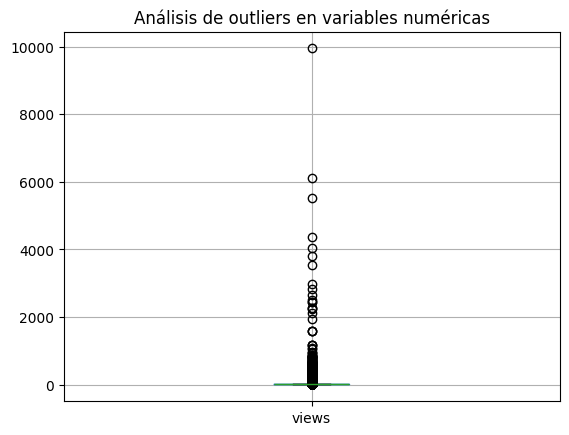

In [174]:
postings[['views']].boxplot()
plt.title('Análisis de outliers en variables numéricas')
plt.show()

In [175]:
postings['views'].describe()

count    101858.000000
mean         10.541352
std          61.067389
min           1.000000
25%           3.000000
50%           4.000000
75%           7.000000
max        9949.000000
Name: views, dtype: float64

Observando la gráfica y la información de la celda anterior se llega a la conclusión de que hay muchos outliers. Los valores más altos pueden ser errores, ya que el 75% de los datos son menores que 7. Por eso, decidimos tener en cuenta las filas en las que las visualizaciones son menores a 300.

In [176]:
postings = postings[postings['views']<300]

In [177]:
postings['views'].describe()

count    101685.000000
mean          9.122496
std          18.653672
min           1.000000
25%           3.000000
50%           4.000000
75%           7.000000
max         299.000000
Name: views, dtype: float64

In [178]:
(1-101685/101858)*100

0.16984429303540383

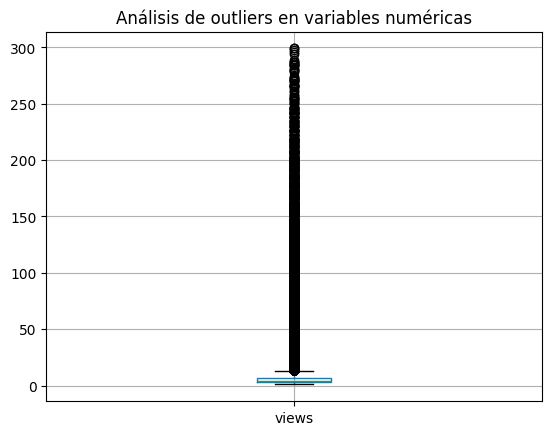

In [179]:
postings[['views']].boxplot()
plt.title('Análisis de outliers en variables numéricas')
plt.show()

# UNIONES TABLAS

In [180]:
postings = postings.merge(industrias_compañias, left_on='company_id',right_on='company_id')
postings

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,industry
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate
1,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants
2,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,"New Hyde Park, NY",766262,16.0,11040,FULL_TIME,Entry level,Law Practice
3,91700727,Downtown Raleigh Alliance,Economic Development and Planning Intern,"Raleigh, NC",1481176,9.0,27601,INTERNSHIP,Entry level,Non-profit Organizations
4,1218575,Children's Nebraska,Respiratory Therapist,"Omaha, NE",721189,3.0,68102,FULL_TIME,Mid-Senior level,Hospitals and Health Care
...,...,...,...,...,...,...,...,...,...,...
101677,3906265414,"TalentBurst, an Inc 5000 company",Contract Administrator,"Irvine, CA",122451,1.0,92602,CONTRACT,Mid-Senior level,Staffing and Recruiting
101678,3906266272,"TalentBurst, an Inc 5000 company",Quality Engineer,"Irvine, CA",122451,1.0,92602,CONTRACT,Mid-Senior level,Staffing and Recruiting
101679,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice
101680,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs


In [181]:
postings = postings.rename(columns={'industry': 'INDUSTRIA_COMPAÑIA'})

In [182]:
postings = postings.merge(industria_oferta, left_on='job_id',right_on='job_id')
postings

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,INDUSTRIA_COMPAÑIA,industry_id
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate,44
1,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants,32
2,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,"New Hyde Park, NY",766262,16.0,11040,FULL_TIME,Entry level,Law Practice,9
3,91700727,Downtown Raleigh Alliance,Economic Development and Planning Intern,"Raleigh, NC",1481176,9.0,27601,INTERNSHIP,Entry level,Non-profit Organizations,3202
4,1218575,Children's Nebraska,Respiratory Therapist,"Omaha, NE",721189,3.0,68102,FULL_TIME,Mid-Senior level,Hospitals and Health Care,14
...,...,...,...,...,...,...,...,...,...,...,...
129950,3906266272,"TalentBurst, an Inc 5000 company",Quality Engineer,"Irvine, CA",122451,1.0,92602,CONTRACT,Mid-Senior level,Staffing and Recruiting,15
129951,3906266272,"TalentBurst, an Inc 5000 company",Quality Engineer,"Irvine, CA",122451,1.0,92602,CONTRACT,Mid-Senior level,Staffing and Recruiting,12
129952,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,9
129953,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs,69


In [183]:
postings = postings.merge(industria_oferta_completo, left_on='industry_id',right_on='industry_id')
postings

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,INDUSTRIA_COMPAÑIA,industry_id,industry_name
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate,44,Real Estate
1,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants,32,Restaurants
2,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,"New Hyde Park, NY",766262,16.0,11040,FULL_TIME,Entry level,Law Practice,9,Law Practice
3,91700727,Downtown Raleigh Alliance,Economic Development and Planning Intern,"Raleigh, NC",1481176,9.0,27601,INTERNSHIP,Entry level,Non-profit Organizations,3202,Non-profit Organization Management
4,1218575,Children's Nebraska,Respiratory Therapist,"Omaha, NE",721189,3.0,68102,FULL_TIME,Mid-Senior level,Hospitals and Health Care,14,Hospitals and Health Care
...,...,...,...,...,...,...,...,...,...,...,...,...
129950,3906266272,"TalentBurst, an Inc 5000 company",Quality Engineer,"Irvine, CA",122451,1.0,92602,CONTRACT,Mid-Senior level,Staffing and Recruiting,15,Pharmaceutical Manufacturing
129951,3906266272,"TalentBurst, an Inc 5000 company",Quality Engineer,"Irvine, CA",122451,1.0,92602,CONTRACT,Mid-Senior level,Staffing and Recruiting,12,Biotechnology Research
129952,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,9,Law Practice
129953,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs,69,Education Administration Programs


In [184]:
postings = postings.rename(columns={'industry_name': 'INDUSTRIA_OFERTA'})

In [185]:
postings = postings.merge(jobs_skills, left_on='job_id',right_on='job_id', how = 'left')
postings

# En este merge se han casi duplicado las filas de job_id.
# Esto es porque un mismo job id puede tener varias skills relacionadas entonces al hacer el merge se crea una fila nueva con la misma informacion en todas las columnas para cada skill que tenga esa oferta de trabajo
# Por otro lado merge hace unión tipo inner por defecto, pero como no queremos perder información de las filas que no tengan coindidencias exactas hacemos tipo de unión left, para conservar las filas de la tabla postings que no tengan coincidencias en la tabla de skills
# Cuidado con no duplicar la información en las agrupaciones posteriores.

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,INDUSTRIA_COMPAÑIA,industry_id,INDUSTRIA_OFERTA,skill_abr
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate,44,Real Estate,MRKT
1,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate,44,Real Estate,SALE
2,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants,32,Restaurants,MGMT
3,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants,32,Restaurants,MNFC
4,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,"New Hyde Park, NY",766262,16.0,11040,FULL_TIME,Entry level,Law Practice,9,Law Practice,OTHR
...,...,...,...,...,...,...,...,...,...,...,...,...,...
224404,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,9,Law Practice,LGL
224405,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,9,Law Practice,BD
224406,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs,69,Education Administration Programs,SALE
224407,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs,69,Education Administration Programs,BD


In [186]:
postings = postings.merge(clasificacion_skills, left_on='skill_abr',right_on='skill_abr')
postings

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,INDUSTRIA_COMPAÑIA,industry_id,INDUSTRIA_OFERTA,skill_abr,skill_name
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate,44,Real Estate,MRKT,Marketing
1,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate,44,Real Estate,SALE,Sales
2,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants,32,Restaurants,MGMT,Management
3,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants,32,Restaurants,MNFC,Manufacturing
4,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,"New Hyde Park, NY",766262,16.0,11040,FULL_TIME,Entry level,Law Practice,9,Law Practice,OTHR,Other
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
223393,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,9,Law Practice,LGL,Legal
223394,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,9,Law Practice,BD,Business Development
223395,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs,69,Education Administration Programs,SALE,Sales
223396,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs,69,Education Administration Programs,BD,Business Development


In [187]:
postings = postings.merge(latitudes_longitudes, left_on='zip_code',right_on='ZIP', how = 'left')
postings

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,INDUSTRIA_COMPAÑIA,industry_id,INDUSTRIA_OFERTA,skill_abr,skill_name,ZIP,LAT,LNG
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate,44,Real Estate,MRKT,Marketing,08540,40.363010,-74.655321
1,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate,44,Real Estate,SALE,Sales,08540,40.363010,-74.655321
2,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants,32,Restaurants,MGMT,Management,45202,39.109356,-84.502584
3,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants,32,Restaurants,MNFC,Manufacturing,45202,39.109356,-84.502584
4,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,"New Hyde Park, NY",766262,16.0,11040,FULL_TIME,Entry level,Law Practice,9,Law Practice,OTHR,Other,11040,40.745347,-73.680292
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
223393,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,9,Law Practice,LGL,Legal,94595,37.871950,-122.069383
223394,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,9,Law Practice,BD,Business Development,94595,37.871950,-122.069383
223395,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs,69,Education Administration Programs,SALE,Sales,99201,47.662360,-117.437255
223396,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs,69,Education Administration Programs,BD,Business Development,99201,47.662360,-117.437255


In [188]:
postings

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,INDUSTRIA_COMPAÑIA,industry_id,INDUSTRIA_OFERTA,skill_abr,skill_name,ZIP,LAT,LNG
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate,44,Real Estate,MRKT,Marketing,08540,40.363010,-74.655321
1,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate,44,Real Estate,SALE,Sales,08540,40.363010,-74.655321
2,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants,32,Restaurants,MGMT,Management,45202,39.109356,-84.502584
3,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants,32,Restaurants,MNFC,Manufacturing,45202,39.109356,-84.502584
4,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,"New Hyde Park, NY",766262,16.0,11040,FULL_TIME,Entry level,Law Practice,9,Law Practice,OTHR,Other,11040,40.745347,-73.680292
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
223393,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,9,Law Practice,LGL,Legal,94595,37.871950,-122.069383
223394,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,9,Law Practice,BD,Business Development,94595,37.871950,-122.069383
223395,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs,69,Education Administration Programs,SALE,Sales,99201,47.662360,-117.437255
223396,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs,69,Education Administration Programs,BD,Business Development,99201,47.662360,-117.437255


# CREACIÓN COLUMNAS NUEVAS

Para agrupar por region hemos creado nuestra clasificación personal de regiones de estados unidos que vamos a hacer en función al primer dígito del código postal. Entonces, primero creamos una columna nueva que sea ese dígito. Después, creamos un diccionario con la clasificación y luego usamos la función map para crear la columna de región en base al diccionario creado.


In [189]:
postings['primer_digito_codigo_postal'] = postings['zip_code'].astype(str).str[0]


region_map = {
    '0': 'Noreste',
    '1': 'Noreste Medio / Atlántico Norte',
    '2': 'Este Medio /Atlántico Medio',
    '3': 'Sureste',
    '4': 'Centro Noroeste',
    '5': 'Centro Norte',
    '6': 'Centro Medio / Grandes Llanuras',
    '7': 'Centro Sur / Suroeste Medio',
    '8': 'Oeste Medio / Montañas',
    '9': 'Oeste / Costa del Pacífico'
}


postings['region'] = postings['primer_digito_codigo_postal'].map(region_map)

<img src="images/zipcodes.png" alt="Mapa USA" style="width:700px; height:auto; margin-right:20px;"/>

Además, para tener otra clasificación más detallada y obtener información por estado, hemos creado otra columna a partir de la localizacion que ya venía en el dataset. Para ello la hemos dividio por el delimitador, quedándonos en dos columnas separadas el nombre de la ciudad y el estado al que pertenece abreviado. Luego hemos creado una clasificación con un diccionario y hemos usado la funcion map otra vez para tener una nueva columna con el nombre completo del estado.


In [190]:
postings[['ciudad','estado']] = postings['location'].str.split(',', expand=True)

estados_nombre_completo = {
    'AL': 'Alabama', 'AK': 'Alaska', 'AZ': 'Arizona', 'AR': 'Arkansas',
    'CA': 'California', 'CO': 'Colorado', 'CT': 'Connecticut', 'DE': 'Delaware',
    'DC': 'District of Columbia', 'FL': 'Florida', 'GA': 'Georgia', 'HI': 'Hawaii',
    'ID': 'Idaho', 'IL': 'Illinois', 'IN': 'Indiana', 'IA': 'Iowa',
    'KS': 'Kansas', 'KY': 'Kentucky', 'LA': 'Louisiana', 'ME': 'Maine',
    'MD': 'Maryland', 'MA': 'Massachusetts', 'MI': 'Michigan', 'MN': 'Minnesota',
    'MS': 'Mississippi', 'MO': 'Missouri', 'MT': 'Montana', 'NE': 'Nebraska',
    'NV': 'Nevada', 'NH': 'New Hampshire', 'NJ': 'New Jersey', 'NM': 'New Mexico',
    'NY': 'New York', 'NC': 'North Carolina', 'ND': 'North Dakota', 'OH': 'Ohio',
    'OK': 'Oklahoma', 'OR': 'Oregon', 'PA': 'Pennsylvania', 'RI': 'Rhode Island',
    'SC': 'South Carolina', 'SD': 'South Dakota', 'TN': 'Tennessee', 'TX': 'Texas',
    'UT': 'Utah', 'VT': 'Vermont', 'VA': 'Virginia', 'WA': 'Washington',
    'WV': 'West Virginia', 'WI': 'Wisconsin', 'WY': 'Wyoming'
}

postings['estado_completo'] = postings['estado'].str.strip().map(estados_nombre_completo)

# ANÁLISIS DE DATOS

### OFERTAS POR REGIÓN DE ESTADOS UNIDOS

Primero para ver a grandes rasgos en que regiones de Estados Unidos se agrupan las ofertas de trabajo agrupamos las regiones por el recuento único (debido a que si hiciéramos el recuento duplicaríamos información por el merge de las skills).

Por otro lado se ha agrupado también por el promedio de latitudes y longitudes con el objetivo de tener un centroide aproximado de referencia de cada región. Aunque hay que ser conscientes de que este punto centroide estará sesgado hacia las zonas donde más ofertas haya.


In [191]:
agrupacion_zonas = postings.groupby('region').agg(count=('job_id', 'nunique'),LAT=('LAT', 'mean'),LNG=('LNG', 'mean')).reset_index()
agrupacion_zonas

,region,count,LAT,LNG
0,Centro Medio / Grandes Llanuras,7657,40.506201,-90.668710
1,Centro Noroeste,8888,40.771868,-84.213287
2,Centro Norte,4976,44.170451,-92.898330
3,Centro Sur / Suroeste Medio,12371,31.658668,-96.317587
4,Este Medio /Atlántico Medio,13128,37.005062,-78.615638
5,Noreste,9049,41.654705,-72.660776
6,Noreste Medio / Atlántico Norte,9895,40.886586,-75.437476
7,Oeste / Costa del Pacífico,15243,38.243267,-121.345332
8,Oeste Medio / Montañas,7311,37.351498,-110.432372
9,Sureste,12042,31.151759,-83.718648


In [192]:
fig = px.scatter_mapbox(
    agrupacion_zonas,
    lat='LAT',
    lon='LNG',
    size='count',
    size_max=40,
    color='count',
    hover_name='region',
    hover_data=['count'],
    color_continuous_scale="Viridis",
    zoom=3,
    mapbox_style="open-street-map",
    width=1200,
    height=800,
    opacity=1
)

fig.update_layout(
    title_text="Distribución geográfica de ofertas de empleo en LinkedIn",
    title_font=dict(size=30, family='Arial', color='black'),
    title_x=0.5  # Centra el título
)

fig.show()

C:\Users\david\AppData\Local\Temp\ipykernel_16120\2434323971.py:1: DeprecationWarning:

*scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/



<img src="images/mapa plotly.png" alt="Mapa USA" style="width:700px; height:auto; margin-right:20px;"/>

Este es el gráfico de plotly para crear mapas que requiere la agrupación que hemos hecho.

- 'size' indica en función de que variable varía el tamaño de los puntos, 'size_max' es para aumentar o disminuir el tamaño de todos los puntos para verlo mejor, 'color' sirve para que la escala de colores de los puntos vaya en función de la variable count

- 'hover_name' y 'hover_data' sirve para derterminar que aparece cuando poner el cursor encima del punto, 'color_continuous_scale' para determinar la paleta de la escala, 'zoom' para la distancia a la que se ve el mapa

- 'width' y 'height' para el ancho y alto del mapa y 'opacity' para que los puntos no sean transparentes.

Se puede observar claramente que la mayoría de ofertas de trabajo se encuentran agupadas en las regiones costeras de Estados Unidos, siendo el Atlántico medio y la costa del Pacífico las dos principales regiones mientras que la zona montañosa del oeste y el centro norte son las zonas en las que menos ofertas se ponen en LinkedIn.

### EMPRESAS POR INDUSTRIA

Ahora vamos a analizar el número de empresas por industria. Primero, se eliminan los *'job_id'* duplicados.

In [193]:
postings_no_duplicados = postings.drop_duplicates(subset='job_id')
postings_no_duplicados

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,INDUSTRIA_COMPAÑIA,...,skill_abr,skill_name,ZIP,LAT,LNG,primer_digito_codigo_postal,region,ciudad,estado,estado_completo
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,"Princeton, NJ",2774458,20.0,08540,FULL_TIME,Mid-Senior level,Real Estate,...,MRKT,Marketing,08540,40.363010,-74.655321,0,Noreste,Princeton,NJ,New Jersey
2,10998357,The National Exemplar,Assitant Restaurant Manager,"Cincinnati, OH",64896719,8.0,45202,FULL_TIME,Director,Restaurants,...,MGMT,Management,45202,39.109356,-84.502584,4,Centro Noroeste,Cincinnati,OH,Ohio
4,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,"New Hyde Park, NY",766262,16.0,11040,FULL_TIME,Entry level,Law Practice,...,OTHR,Other,11040,40.745347,-73.680292,1,Noreste Medio / Atlántico Norte,New Hyde Park,NY,New York
5,91700727,Downtown Raleigh Alliance,Economic Development and Planning Intern,"Raleigh, NC",1481176,9.0,27601,INTERNSHIP,Entry level,Non-profit Organizations,...,PRJM,Project Management,27601,35.773632,-78.634457,2,Este Medio /Atlántico Medio,Raleigh,NC,North Carolina
6,1218575,Children's Nebraska,Respiratory Therapist,"Omaha, NE",721189,3.0,68102,FULL_TIME,Mid-Senior level,Hospitals and Health Care,...,HCPR,Health Care Provider,68102,41.262140,-95.933833,6,Centro Medio / Grandes Llanuras,Omaha,NE,Nebraska
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
223381,3906265414,"TalentBurst, an Inc 5000 company",Contract Administrator,"Irvine, CA",122451,1.0,92602,CONTRACT,Mid-Senior level,Staffing and Recruiting,...,LGL,Legal,92602,33.754048,-117.752273,9,Oeste / Costa del Pacífico,Irvine,CA,California
223390,3906266272,"TalentBurst, an Inc 5000 company",Quality Engineer,"Irvine, CA",122451,1.0,92602,CONTRACT,Mid-Senior level,Staffing and Recruiting,...,ENG,Engineering,92602,33.754048,-117.752273,9,Oeste / Costa del Pacífico,Irvine,CA,California
223393,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,...,LGL,Legal,94595,37.871950,-122.069383,9,Oeste / Costa del Pacífico,Walnut Creek,CA,California
223395,3906267131,EPS Learning,"Account Executive, Oregon/Washington","Spokane, WA",90552133,3.0,99201,FULL_TIME,Mid-Senior level,Education Administration Programs,...,SALE,Sales,99201,47.662360,-117.437255,9,Oeste / Costa del Pacífico,Spokane,WA,Washington


A continuación, se agrupan las empresas por industrias.

In [194]:
empresas_sectores = postings_no_duplicados.groupby(['INDUSTRIA_COMPAÑIA'])['company_name'].count().reset_index()
empresas_sectores = empresas_sectores.rename(columns={'company_name':'number_companies'})
empresas_sectores = empresas_sectores.sort_values(by=['number_companies'],ascending=False)
empresas_sectores

,INDUSTRIA_COMPAÑIA,number_companies
122,Staffing and Recruiting,15251
54,Hospitals and Health Care,14076
111,Retail,9081
56,IT Services and IT Consulting,8212
40,Financial Services,4729
...,...,...
6,Animation and Post-production,2
4,Alternative Dispute Resolution,1
69,Legislative Offices,1
135,Warehousing and Storage,1


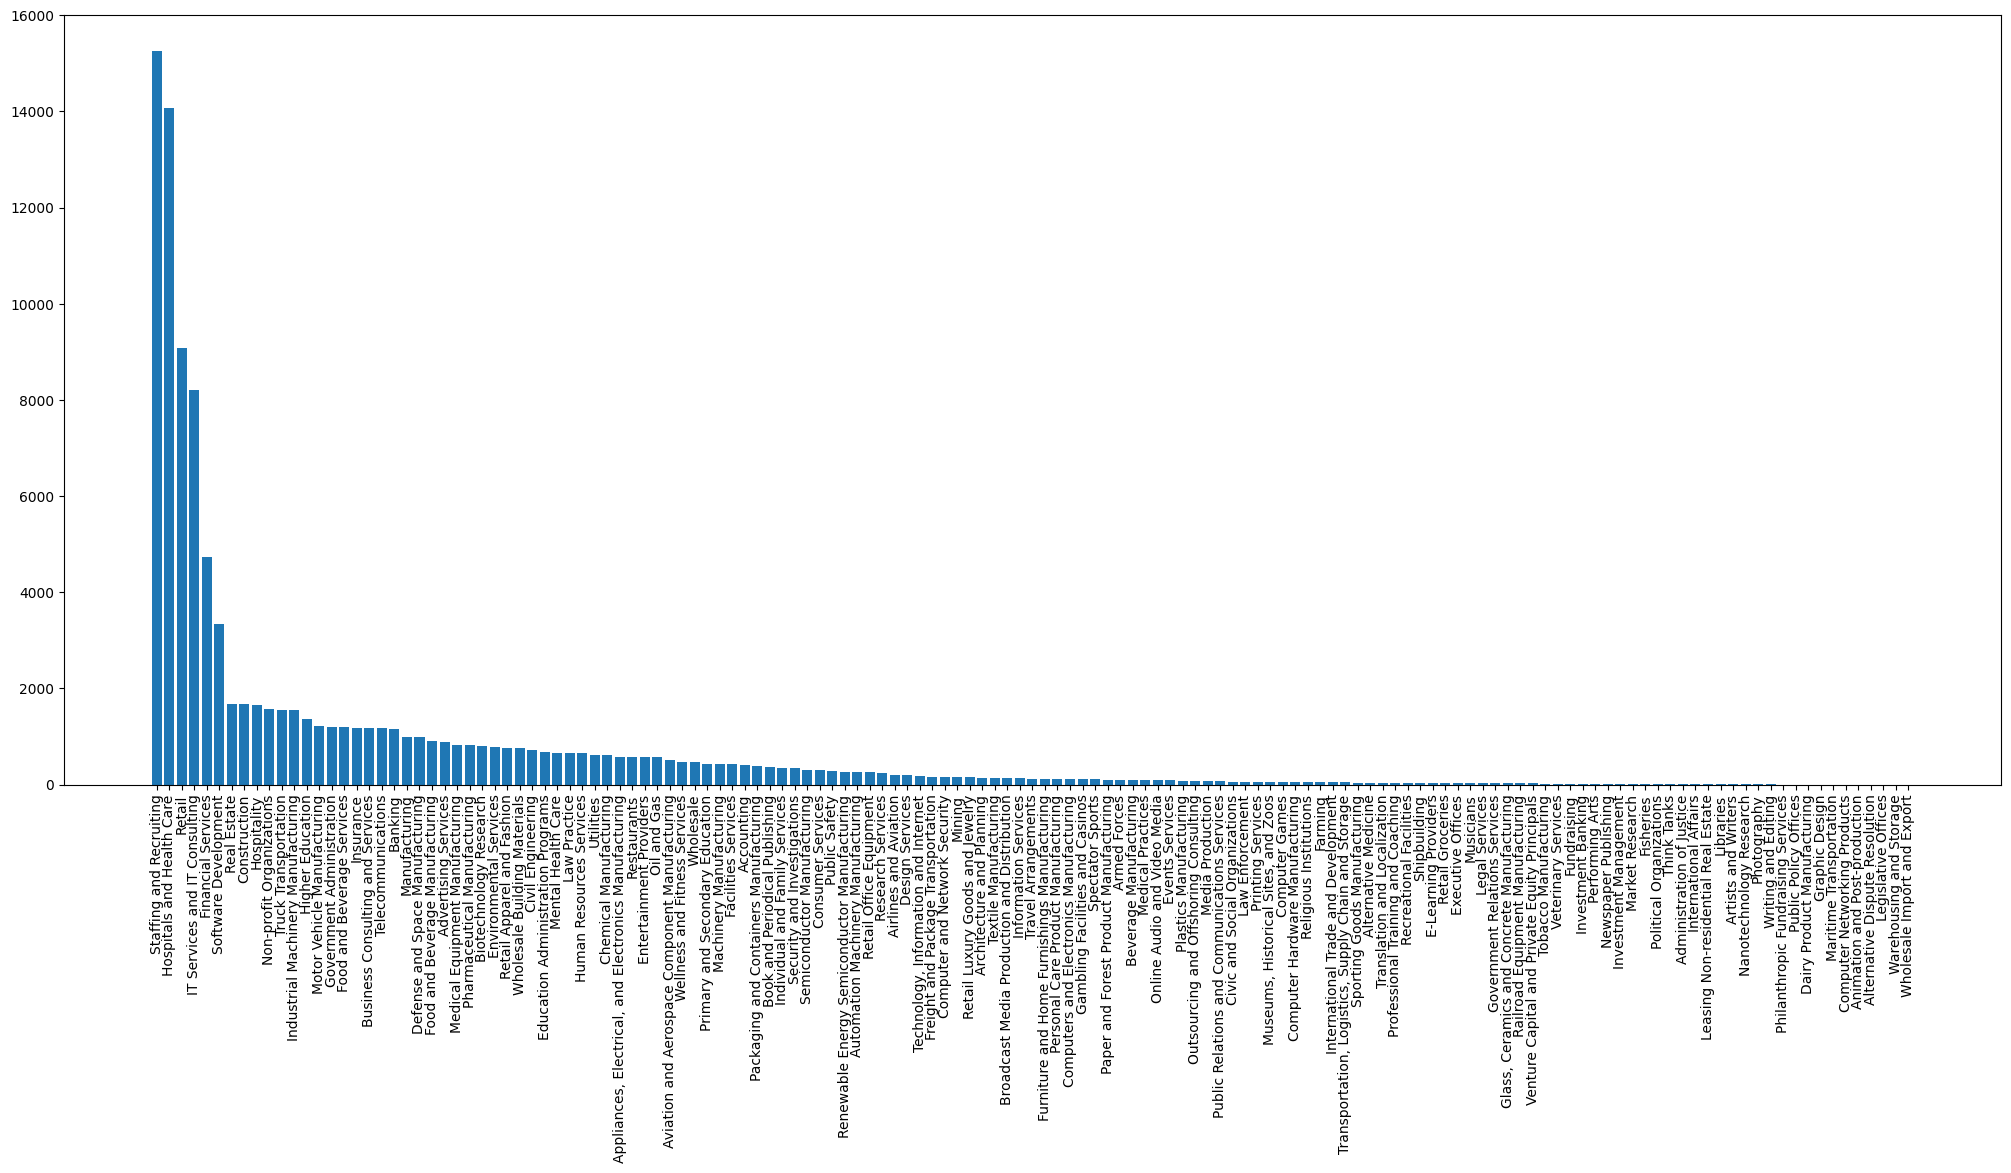

In [195]:
plt.figure(figsize=(25,10))
plt.bar(empresas_sectores['INDUSTRIA_COMPAÑIA'],empresas_sectores['number_companies'])
plt.xticks(rotation=90)
plt.show()

Como el gráfico no se puede interpretar con claridad debido a la gran cantidad de sectores, se agrupan los sectores que tienen menos empresas.

In [196]:
empresas_sectores_altos = empresas_sectores[empresas_sectores['number_companies']>=1700]
empresas_sectores_bajos = empresas_sectores[empresas_sectores['number_companies']<1700].sum()
empresas_sectores_altos.loc[len(empresas_sectores_altos)] = ['Otros',empresas_sectores_bajos['number_companies']]
empresas_sectores_agrupados = empresas_sectores_altos
empresas_sectores_agrupados

C:\Users\david\AppData\Local\Temp\ipykernel_16120\3785194350.py:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,INDUSTRIA_COMPAÑIA,number_companies
122,Staffing and Recruiting,15251
54,Hospitals and Health Care,14076
111,Retail,9081
56,IT Services and IT Consulting,8212
40,Financial Services,4729
119,Software Development,3342
6,Otros,45868


In [197]:
empresas_sectores_agrupados['number_companies']/empresas_sectores_agrupados['number_companies'].sum()*100

122    15.166221
54     13.997753
111     9.030519
56      8.166350
40      4.702712
119     3.323422
6      45.613023
Name: number_companies, dtype: float64

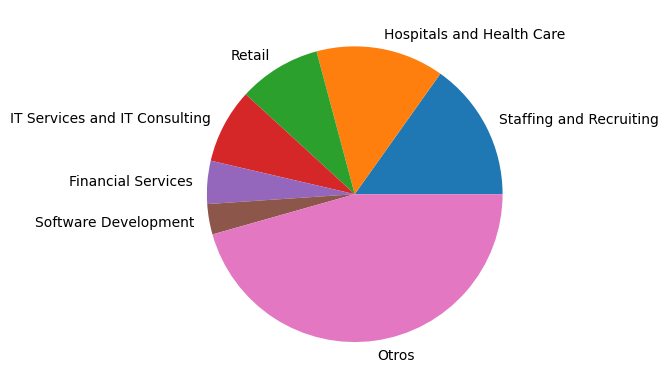

In [198]:
plt.pie(empresas_sectores_agrupados['number_companies'],labels=empresas_sectores_agrupados['INDUSTRIA_COMPAÑIA'])
plt.show()

En el último gráfico se puede ver que los sectores con mayor número de empresas son *Staffing and Recruiting*, *Hospitals and Health Care*, *Retail*, *IT Services and IT Consulting*, *Financial Services* y *Software Development*.

### VISUALIZACIONES POR INDUSTRIA

También es interesante ver el número de visualizaciones que cada sector tiene.

In [199]:
views_sectores = postings_no_duplicados.groupby(['INDUSTRIA_COMPAÑIA'])['views'].sum().reset_index()
views_sectores = views_sectores.sort_values(by=['views'],ascending=False)
views_sectores

,INDUSTRIA_COMPAÑIA,views
122,Staffing and Recruiting,169129.0
56,IT Services and IT Consulting,142629.0
54,Hospitals and Health Care,75165.0
119,Software Development,49084.0
111,Retail,48300.0
...,...,...
73,Maritime Transportation,11.0
139,Wholesale Import and Export,9.0
69,Legislative Offices,6.0
4,Alternative Dispute Resolution,3.0


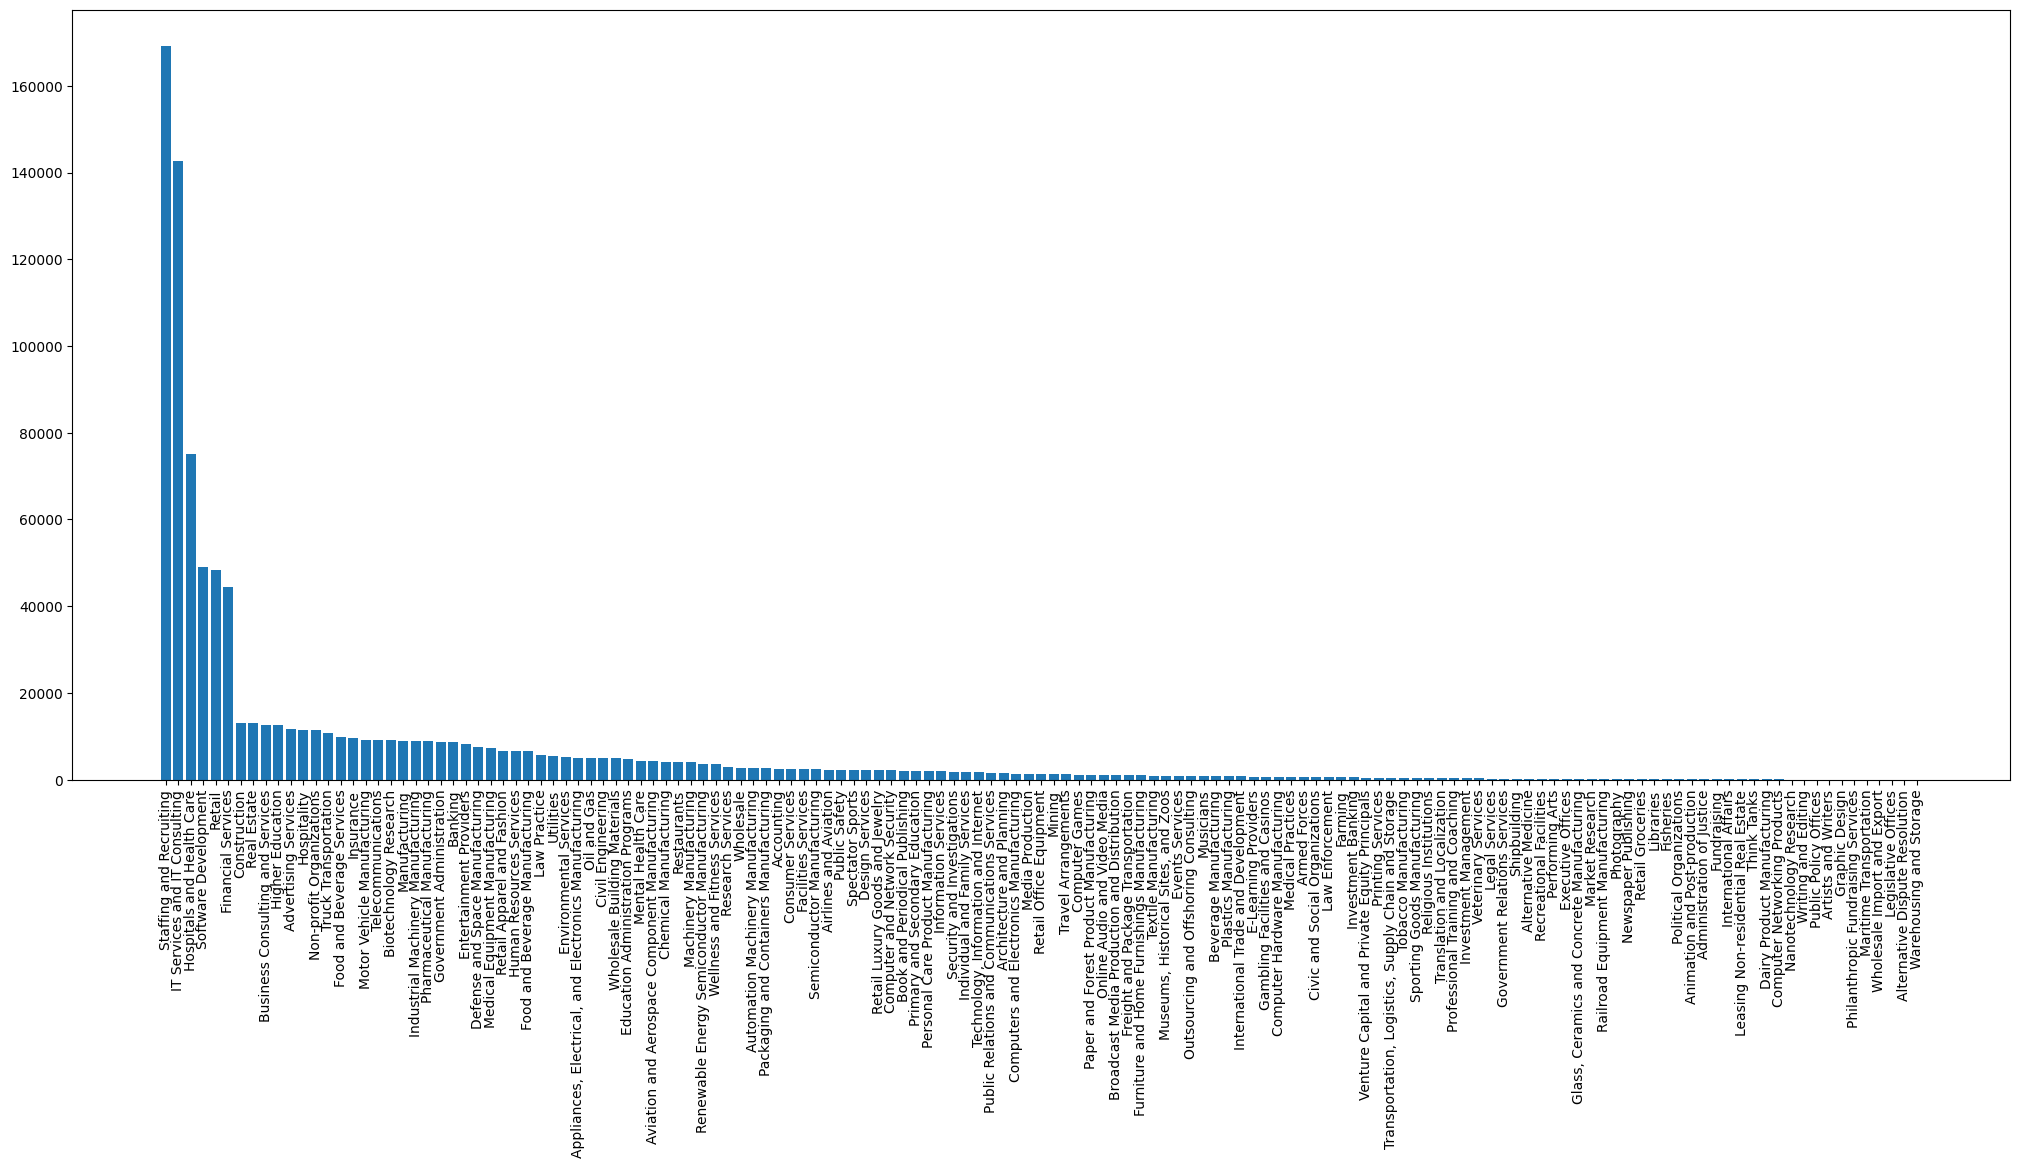

In [200]:
plt.figure(figsize=(25,10))
plt.bar(views_sectores['INDUSTRIA_COMPAÑIA'],views_sectores['views'])
plt.xticks(rotation=90)
plt.show()

Por la misma razón que en el apartado anterior, se agrupan las industrias que tienen menor número de visualizaciones.

In [201]:
views_sectores_altos = views_sectores[views_sectores['views']>=40000]
views_sectores_bajos = views_sectores[views_sectores['views']<40000].sum()
views_sectores_altos.loc[len(views_sectores_altos)] = ['Otros',views_sectores_bajos['views']]
views_sectores_agrupados = views_sectores_altos
views_sectores_agrupados

C:\Users\david\AppData\Local\Temp\ipykernel_16120\2666663122.py:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,INDUSTRIA_COMPAÑIA,views
122,Staffing and Recruiting,169129.0
56,IT Services and IT Consulting,142629.0
54,Hospitals and Health Care,75165.0
119,Software Development,49084.0
111,Retail,48300.0
40,Financial Services,44524.0
6,Otros,383411.0


In [202]:
views_sectores_agrupados['views']/views_sectores_agrupados['views'].sum()*100

122    18.539927
56     15.634996
54      8.239590
119     5.380590
111     5.294648
40      4.880722
6      42.029527
Name: views, dtype: float64

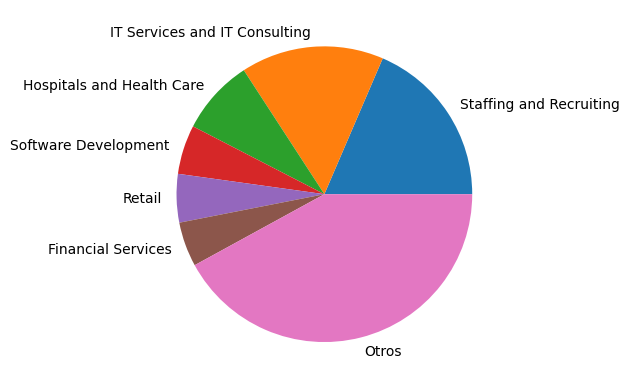

In [203]:
plt.pie(views_sectores_agrupados['views'],labels=views_sectores_agrupados['INDUSTRIA_COMPAÑIA'])
plt.show()

En este caso, los sectores que tienen un mayor número de visualizaciones son: *Staffing and Recruiting*, *IT Services and IT Consulting*, *Hospitals and Health Care*, *Software Development*, *Retail* y *Financial Services*. Estos son los sectores con un mayor número de empresas en esta tabla (como se puede ver en el apartado anterior).

### INDUSTRIAS MÁS IMPORTANTES SEGÚN EL ZIP CODE (PRIMERA CIFRA)

Otra cosa interesante que podemos estudiar es el siguiente: ¿cuáles son los sectores más importantes según la región de Estados Unidos? Para ello, utilizaremos la primera cifra del ZIP Code.

In [204]:
sectores_zip = postings_no_duplicados.groupby(['INDUSTRIA_COMPAÑIA','primer_digito_codigo_postal'])['company_name'].count().reset_index()
sectores_zip = sectores_zip.rename(columns={'company_name':'number_companies'})
sectores_zip = sectores_zip.sort_values(by=['primer_digito_codigo_postal','number_companies'],ascending=False)
sectores_zip

,INDUSTRIA_COMPAÑIA,primer_digito_codigo_postal,number_companies
1047,Staffing and Recruiting,9,2539
473,Hospitals and Health Care,9,1780
493,IT Services and IT Consulting,9,1281
948,Retail,9,1154
1017,Software Development,9,1025
...,...,...,...
546,Investment Banking,0,1
619,Market Research,0,1
695,Musicians,0,1
819,Political Organizations,0,1


Ahora, seleccionamos los 10 sectores que tienen un mayor número de empresas en cada región y los representamos en gráficos de barras.

In [205]:
count_9 = sectores_zip[sectores_zip['primer_digito_codigo_postal']=='9'].head(10)
count_8 = sectores_zip[sectores_zip['primer_digito_codigo_postal']=='8'].head(10)
count_7 = sectores_zip[sectores_zip['primer_digito_codigo_postal']=='7'].head(10)
count_6 = sectores_zip[sectores_zip['primer_digito_codigo_postal']=='6'].head(10)
count_5 = sectores_zip[sectores_zip['primer_digito_codigo_postal']=='5'].head(10)
count_4 = sectores_zip[sectores_zip['primer_digito_codigo_postal']=='4'].head(10)
count_3 = sectores_zip[sectores_zip['primer_digito_codigo_postal']=='3'].head(10)
count_2 = sectores_zip[sectores_zip['primer_digito_codigo_postal']=='2'].head(10)
count_1 = sectores_zip[sectores_zip['primer_digito_codigo_postal']=='1'].head(10)
count_0 = sectores_zip[sectores_zip['primer_digito_codigo_postal']=='0'].head(10)

Juntamos todos los gráficos en uno solo para verlos con mayor claridad.

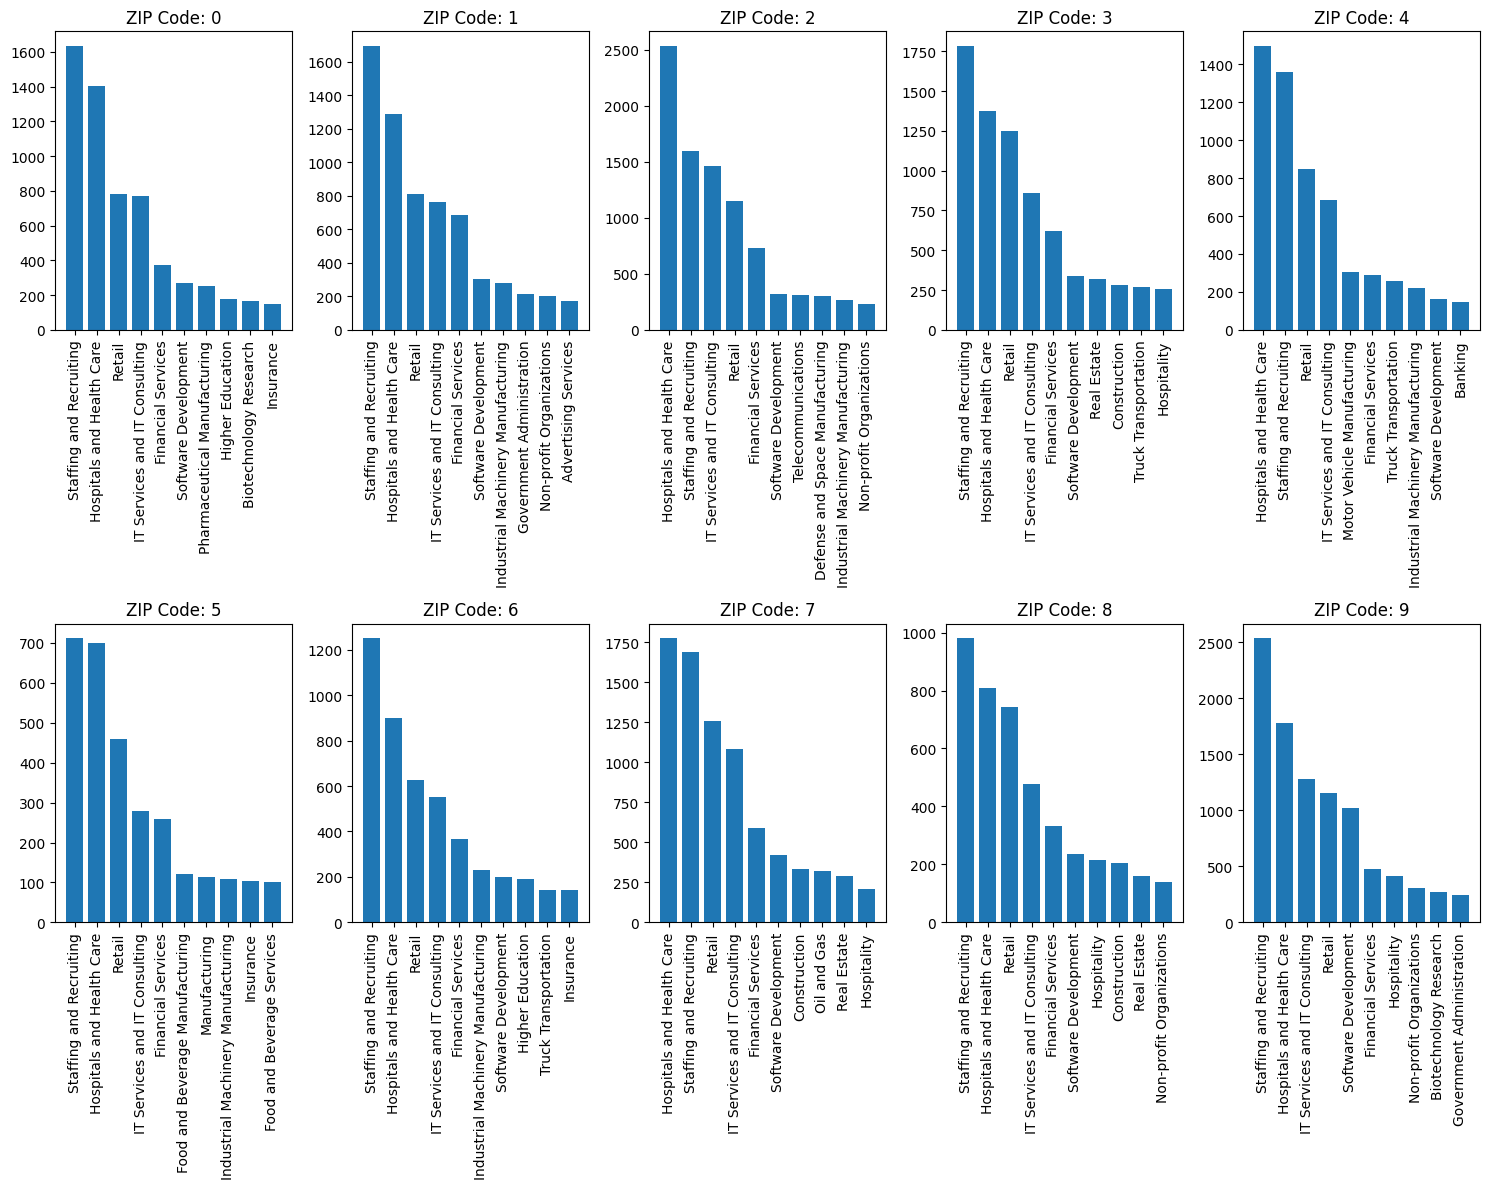

In [206]:
plt.figure(figsize=(15,12))

plt.subplot(2,5,1)
plt.bar(count_0['INDUSTRIA_COMPAÑIA'],count_0['number_companies'])
plt.xticks(rotation=90)
plt.title('ZIP Code: 0')

plt.subplot(2,5,2)
plt.bar(count_1['INDUSTRIA_COMPAÑIA'],count_1['number_companies'])
plt.xticks(rotation=90)
plt.title('ZIP Code: 1')

plt.subplot(2,5,3)
plt.bar(count_2['INDUSTRIA_COMPAÑIA'],count_2['number_companies'])
plt.xticks(rotation=90)
plt.title('ZIP Code: 2')

plt.subplot(2,5,4)
plt.bar(count_3['INDUSTRIA_COMPAÑIA'],count_3['number_companies'])
plt.xticks(rotation=90)
plt.title('ZIP Code: 3')

plt.subplot(2,5,5)
plt.bar(count_4['INDUSTRIA_COMPAÑIA'],count_4['number_companies'])
plt.xticks(rotation=90)
plt.title('ZIP Code: 4')

plt.subplot(2,5,6)
plt.bar(count_5['INDUSTRIA_COMPAÑIA'],count_5['number_companies'])
plt.xticks(rotation=90)
plt.title('ZIP Code: 5')

plt.subplot(2,5,7)
plt.bar(count_6['INDUSTRIA_COMPAÑIA'],count_6['number_companies'])
plt.xticks(rotation=90)
plt.title('ZIP Code: 6')

plt.subplot(2,5,8)
plt.bar(count_7['INDUSTRIA_COMPAÑIA'],count_7['number_companies'])
plt.xticks(rotation=90)
plt.title('ZIP Code: 7')

plt.subplot(2,5,9)
plt.bar(count_8['INDUSTRIA_COMPAÑIA'],count_8['number_companies'])
plt.xticks(rotation=90)
plt.title('ZIP Code: 8')

plt.subplot(2,5,10)
plt.bar(count_9['INDUSTRIA_COMPAÑIA'],count_9['number_companies'])
plt.xticks(rotation=90)
plt.title('ZIP Code: 9')

plt.tight_layout()
plt.show()

La industria más importante en siete de las diez regiones es *Staffing and Recruiting*, que es el que es el que mayor número de empresas tiene en estos datos y el que más visualizaciones obtiene.

En las otras tres regiones, la industria más importante es *Hospitals and Health Care*, que es la segunda que más empresas tiene.

Hay muchos sectores que se repiten en todas las regiones, pero hay algunos que aparecen en solo algunas. Por ejemplo, la industria *Oil and Gas* solo aparece en la región 7 debido a que en ella se encuentra el estado de Texas, que es uno de los que más petróleo produce.

### ¿DÓNDE ESTÁN LAS OFERTAS A LAS QUE PODEMOS ACCEDER COMO PERSONAS CON POCA O NINGUNA EXPERIENCIA?, QUE INDUSTRIAS LAS OFRECEN, Y CUALES SON LAS SKILLS QUE MAS SE BUSCAN EN DICHOS PUESTOS?

Primero filtramos el dataset de manera que formatted_experience_level que es experiencia requerida sea Internship o Entry level, es decir puestos a los que se puede aplicar con poca experiencia. Además para no modificar el dataframe original se ha puesto la función copy() al final con el objetivo de trabajar con este filtro en un dataframe independiente.

In [207]:
postings_sin_exp = postings[(postings['formatted_experience_level'] == 'Internship') | (postings['formatted_experience_level'] == 'Entry level')].copy()
postings_sin_exp

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,INDUSTRIA_COMPAÑIA,...,skill_abr,skill_name,ZIP,LAT,LNG,primer_digito_codigo_postal,region,ciudad,estado,estado_completo
4,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,"New Hyde Park, NY",766262,16.0,11040,FULL_TIME,Entry level,Law Practice,...,OTHR,Other,11040,40.745347,-73.680292,1,Noreste Medio / Atlántico Norte,New Hyde Park,NY,New York
5,91700727,Downtown Raleigh Alliance,Economic Development and Planning Intern,"Raleigh, NC",1481176,9.0,27601,INTERNSHIP,Entry level,Non-profit Organizations,...,PRJM,Project Management,27601,35.773632,-78.634457,2,Este Medio /Atlántico Medio,Raleigh,NC,North Carolina
13,83789755,OsteoStrong,Osteogenic Loading Coach,"Anchorage, AK",3810432,4.0,99501,FULL_TIME,Entry level,Wellness and Fitness Services,...,OTHR,Other,99501,61.220018,-149.855702,9,Oeste / Costa del Pacífico,Anchorage,AK,Alaska
14,95428182,CLEVELAND KIDS BOOK BANK,Administrative Coordinator,"Cleveland, OH",55624331,1.0,44102,FULL_TIME,Entry level,Non-profit Organizations,...,ADM,Administrative,44102,41.479174,-81.740603,4,Centro Noroeste,Cleveland,OH,Ohio
33,243731357,Fidelity National Title / Law Firm,Legal Secretary,"Phoenix, AZ",1832363,3.0,85003,FULL_TIME,Entry level,Real Estate,...,LGL,Legal,85003,33.450662,-112.078353,8,Oeste Medio / Montañas,Phoenix,AZ,Arizona
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
223364,3906265301,RAND,Bachelor’s Level Research Assistant - Quantita...,"Pittsburgh, PA",165654,4.0,15201,FULL_TIME,Entry level,Think Tanks,...,SCI,Science,15201,40.474410,-79.950968,1,Noreste Medio / Atlántico Norte,Pittsburgh,PA,Pennsylvania
223365,3906265301,RAND,Bachelor’s Level Research Assistant - Quantita...,"Pittsburgh, PA",165654,4.0,15201,FULL_TIME,Entry level,Think Tanks,...,RSCH,Research,15201,40.474410,-79.950968,1,Noreste Medio / Atlántico Norte,Pittsburgh,PA,Pennsylvania
223366,3906265301,RAND,Bachelor’s Level Research Assistant - Quantita...,"Pittsburgh, PA",165654,4.0,15201,FULL_TIME,Entry level,Think Tanks,...,QA,Quality Assurance,15201,40.474410,-79.950968,1,Noreste Medio / Atlántico Norte,Pittsburgh,PA,Pennsylvania
223367,3906265301,RAND,Bachelor’s Level Research Assistant - Quantita...,"Pittsburgh, PA",165654,4.0,15201,FULL_TIME,Entry level,Think Tanks,...,SCI,Science,15201,40.474410,-79.950968,1,Noreste Medio / Atlántico Norte,Pittsburgh,PA,Pennsylvania


Se eliminan los duplicados producidos por el merge de skills.

In [208]:
recuentos = postings_sin_exp.drop_duplicates(subset='job_id')
recuentos

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,INDUSTRIA_COMPAÑIA,...,skill_abr,skill_name,ZIP,LAT,LNG,primer_digito_codigo_postal,region,ciudad,estado,estado_completo
4,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,"New Hyde Park, NY",766262,16.0,11040,FULL_TIME,Entry level,Law Practice,...,OTHR,Other,11040,40.745347,-73.680292,1,Noreste Medio / Atlántico Norte,New Hyde Park,NY,New York
5,91700727,Downtown Raleigh Alliance,Economic Development and Planning Intern,"Raleigh, NC",1481176,9.0,27601,INTERNSHIP,Entry level,Non-profit Organizations,...,PRJM,Project Management,27601,35.773632,-78.634457,2,Este Medio /Atlántico Medio,Raleigh,NC,North Carolina
13,83789755,OsteoStrong,Osteogenic Loading Coach,"Anchorage, AK",3810432,4.0,99501,FULL_TIME,Entry level,Wellness and Fitness Services,...,OTHR,Other,99501,61.220018,-149.855702,9,Oeste / Costa del Pacífico,Anchorage,AK,Alaska
14,95428182,CLEVELAND KIDS BOOK BANK,Administrative Coordinator,"Cleveland, OH",55624331,1.0,44102,FULL_TIME,Entry level,Non-profit Organizations,...,ADM,Administrative,44102,41.479174,-81.740603,4,Centro Noroeste,Cleveland,OH,Ohio
33,243731357,Fidelity National Title / Law Firm,Legal Secretary,"Phoenix, AZ",1832363,3.0,85003,FULL_TIME,Entry level,Real Estate,...,LGL,Legal,85003,33.450662,-112.078353,8,Oeste Medio / Montañas,Phoenix,AZ,Arizona
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
223332,3906264238,CORA Health Services,Physical Therapist,"Doral, FL",59103641,2.0,32757,FULL_TIME,Entry level,Medical Practices,...,HCPR,Health Care Provider,32757,28.773053,-81.638118,3,Sureste,Doral,FL,Florida
223352,3906265244,99 Ranch Market,Picker,"Brooklyn, NY",9662527,4.0,11201,FULL_TIME,Entry level,Retail Groceries,...,MGMT,Management,11201,40.693682,-73.989693,1,Noreste Medio / Atlántico Norte,Brooklyn,NY,New York
223357,3906265278,Associated Bank,React Native Developer,"Milwaukee County, WI",8667,3.0,53202,FULL_TIME,Entry level,Financial Services,...,ENG,Engineering,53202,43.049579,-87.892520,5,Centro Norte,Milwaukee County,WI,Wisconsin
223359,3906265301,RAND,Bachelor’s Level Research Assistant - Quantita...,"Pittsburgh, PA",165654,4.0,15201,FULL_TIME,Entry level,Think Tanks,...,RSCH,Research,15201,40.474410,-79.950968,1,Noreste Medio / Atlántico Norte,Pittsburgh,PA,Pennsylvania


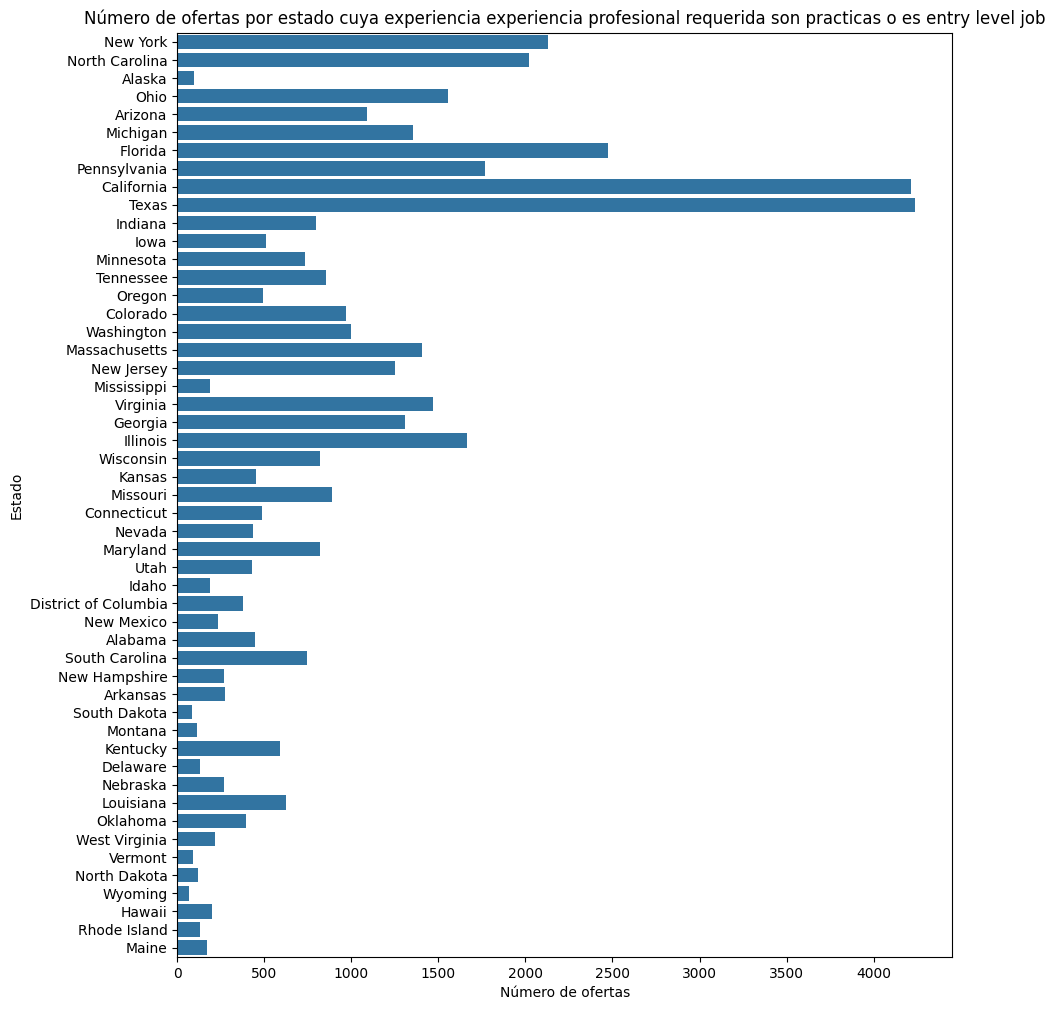

In [209]:
plt.figure(figsize=(10,12))
sns.countplot(data=recuentos, y='estado_completo')
plt.xlabel('Número de ofertas')
plt.ylabel('Estado')
plt.title('Número de ofertas por estado cuya experiencia experiencia profesional requerida son practicas o es entry level job')
plt.show()

Se puede comprobar que los estados en los que más ofertas se publican que requieren poca experiencia se corresponden con las regiones costeras en las que más ofertas se publican. Sin embargo, llama la atención que el estado donde más ofertas que requieren poca experiencia se publican es Texas ya que pertenece a la tercera región que más ofertas se publican.

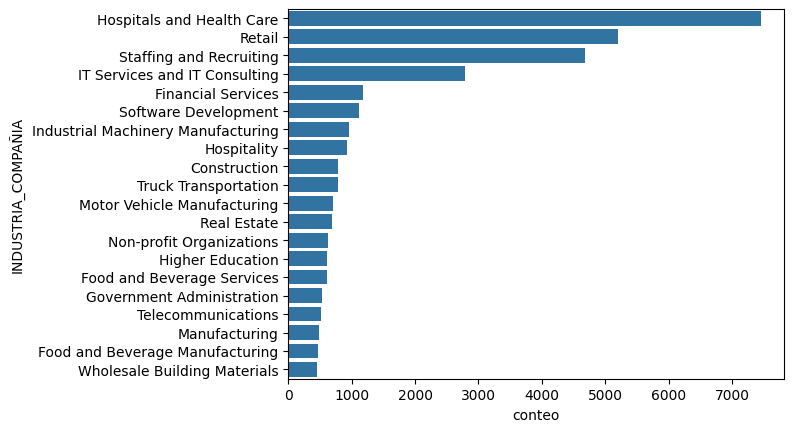

In [210]:
agrupacion = recuentos.groupby('INDUSTRIA_COMPAÑIA').size().nlargest(20).reset_index()
agrupacion = agrupacion.rename(columns={0: 'conteo'})

sns.barplot(data = agrupacion, x = 'conteo', y = 'INDUSTRIA_COMPAÑIA')
plt.show()

El top cinco de industrias a las que pertenecen  las compañías que ofrecen dichas ofertas son principalmente la hospitalaria y atención sanitaria, el retail, recursos humanos y gestión de talento, los servicios IT y los servicios financieros. Mientras que las industrias que ofrecen menos ofertas que requieren poca experiencia son la venta al por mayor, manufacturera, administración del gobierno y telecomunicaciones.

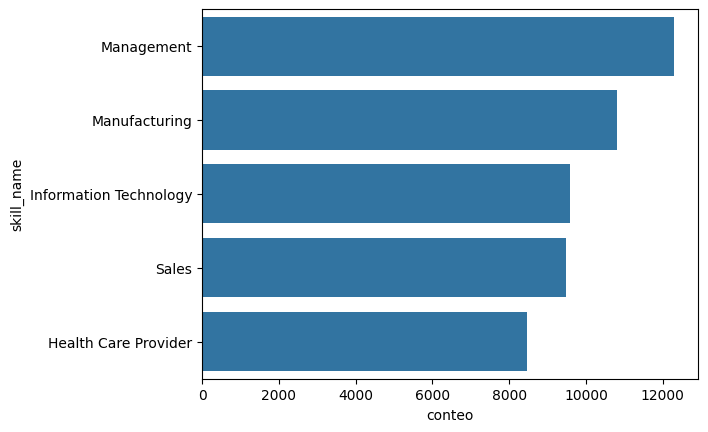

In [211]:
agrupacion = postings_sin_exp.groupby('skill_name').size().nlargest(5).reset_index()
agrupacion = agrupacion.rename(columns={0: 'conteo'})

sns.barplot(data = agrupacion, x = 'conteo', y = 'skill_name')
plt.show()

Las capacidades o conocimientos que más se requieren en dichas ofertas son la gestión/liderazgo,los conocimientos de manufactura, los conocimientos sobre tecnologías de información, ventas y capacidad de proveer atención sanitaria.

### PARA NOSOTROS COMO DATA SCIENTIST, ¿DÓNDE ESTÁN LAS OFERTAS RELACIONADAS CON NUESTRO CAMPO?¿QUÉ HABILIDADES/CONOCIMIENTOS REQUIEREN?

Para filtrar las ofertas de linkedin que pertenecen o se relacionan con la industria de los datos se ha buscado que la cadena de la columna industria oferta contenga la palabra data.

Hay que tener en cuenta que puestos relacionados con otras palabras como IT o software también pueden requerir trabajar con datos o referirse a lo mismo pero por simplicidad nos hemos quedado con ese criterio.


In [212]:
puestos_data = postings[postings['INDUSTRIA_OFERTA'].str.contains('data', case=False, na=False)].copy()
puestos_data

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,INDUSTRIA_COMPAÑIA,...,skill_abr,skill_name,ZIP,LAT,LNG,primer_digito_codigo_postal,region,ciudad,estado,estado_completo
371,3814570200,Mailprotector,Business Development Representative,"Greenville, SC",358231,9.0,29601,FULL_TIME,Mid-Senior level,Computer and Network Security,...,SALE,Sales,29601,34.847112,-82.402264,2,Este Medio /Atlántico Medio,Greenville,SC,South Carolina
372,3814570200,Mailprotector,Business Development Representative,"Greenville, SC",358231,9.0,29601,FULL_TIME,Mid-Senior level,Computer and Network Security,...,BD,Business Development,29601,34.847112,-82.402264,2,Este Medio /Atlántico Medio,Greenville,SC,South Carolina
933,3884429793,Golden Technology,Java Technical Lead,"Cincinnati, OH",2678950,59.0,45202,CONTRACT,Mid-Senior level,IT Services and IT Consulting,...,MGMT,Management,45202,39.109356,-84.502584,4,Centro Noroeste,Cincinnati,OH,Ohio
934,3884429793,Golden Technology,Java Technical Lead,"Cincinnati, OH",2678950,59.0,45202,CONTRACT,Mid-Senior level,IT Services and IT Consulting,...,IT,Information Technology,45202,39.109356,-84.502584,4,Centro Noroeste,Cincinnati,OH,Ohio
935,3884429793,Golden Technology,Java Technical Lead,"Cincinnati, OH",2678950,59.0,45202,CONTRACT,Mid-Senior level,IT Services and IT Consulting,...,ENG,Engineering,45202,39.109356,-84.502584,4,Centro Noroeste,Cincinnati,OH,Ohio
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
205758,3905835032,"TechnoSphere, Inc.",SW Quality Engineer,"Everett, WA",77601,9.0,98201,CONTRACT,Mid-Senior level,IT Services and IT Consulting,...,BD,Business Development,98201,48.006311,-122.210044,9,Oeste / Costa del Pacífico,Everett,WA,Washington
205759,3905835032,"TechnoSphere, Inc.",SW Quality Engineer,"Everett, WA",77601,9.0,98201,CONTRACT,Mid-Senior level,IT Services and IT Consulting,...,IT,Information Technology,98201,48.006311,-122.210044,9,Oeste / Costa del Pacífico,Everett,WA,Washington
210339,3905872787,Radiansys Inc.,"Devops Big data architect Remote(Spark, Python...","Oakland, CA",537246,1.0,94601,FULL_TIME,Mid-Senior level,IT Services and IT Consulting,...,ACCT,Accounting/Auditing,94601,37.775545,-122.218705,9,Oeste / Costa del Pacífico,Oakland,CA,California
210340,3905872787,Radiansys Inc.,"Devops Big data architect Remote(Spark, Python...","Oakland, CA",537246,1.0,94601,FULL_TIME,Mid-Senior level,IT Services and IT Consulting,...,ADM,Administrative,94601,37.775545,-122.218705,9,Oeste / Costa del Pacífico,Oakland,CA,California


In [213]:
agrupacion_estado = puestos_data.groupby('estado_completo').agg(count=('job_id', 'nunique'),LAT=('LAT', 'mean'),LNG=('LNG', 'mean')).reset_index()

In [214]:
fig = px.scatter_mapbox(
    agrupacion_estado,
    lat='LAT',
    lon='LNG',
    color='count',
    color_continuous_scale="Viridis",
    hover_name='estado_completo',
    size_max=20,
    size = 'count',
    zoom=3,
    mapbox_style="open-street-map",
    width=1200,
    height=800,
    opacity=1
)

fig.update_layout(
    title_text="Distribución geográfica de ofertas de empleo en LinkedIn",
    title_font=dict(size=30, family='Arial', color='black'),
    title_x=0.5  # Centra el título
)

fig.show()

C:\Users\david\AppData\Local\Temp\ipykernel_16120\3610741012.py:1: DeprecationWarning:

*scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/



In [215]:
agrupacion_habilidades = puestos_data.groupby('skill_name').agg(numero_trabajos=('job_id', 'nunique')).sort_values(by = 'numero_trabajos',ascending=False).reset_index()
agrupacion_habilidades.head(10)

,skill_name,numero_trabajos
0,Information Technology,29
1,Administrative,21
2,Accounting/Auditing,18
3,Analyst,17
4,Advertising,15
5,Engineering,14
6,Business Development,9
7,Management,9
8,Other,8
9,Consulting,6


Los estados donde más puestos relacionados con los datos se ofrecen son con mucha diferencia California, Nueva York y Texas. Además las habilidades que dichas ofertas requieren son las habilidades de tecnologías de información, administración, auditoría y capacidad de análisis.

### OFERTAS VS PROMEDIO DE VISITAS POR NIVEL DE EXPERIENCIA

Se agruparon las ofertas por su columna formatted_experience_level (por ejemplo: Internship, Entry, Mid, Senior). Se calcularon dos métricas para cada nivel:
o	Número de ofertas publicadas.
o	Promedio de vistas por oferta (indicador del interés que generan).

Como los valores de vistas suelen ser mucho mayores que los de ofertas, se normalizaron (ajustaron proporcionalmente a la misma escala) para poder representarlos juntos.

Para crear un gráfico de barras agrupadas


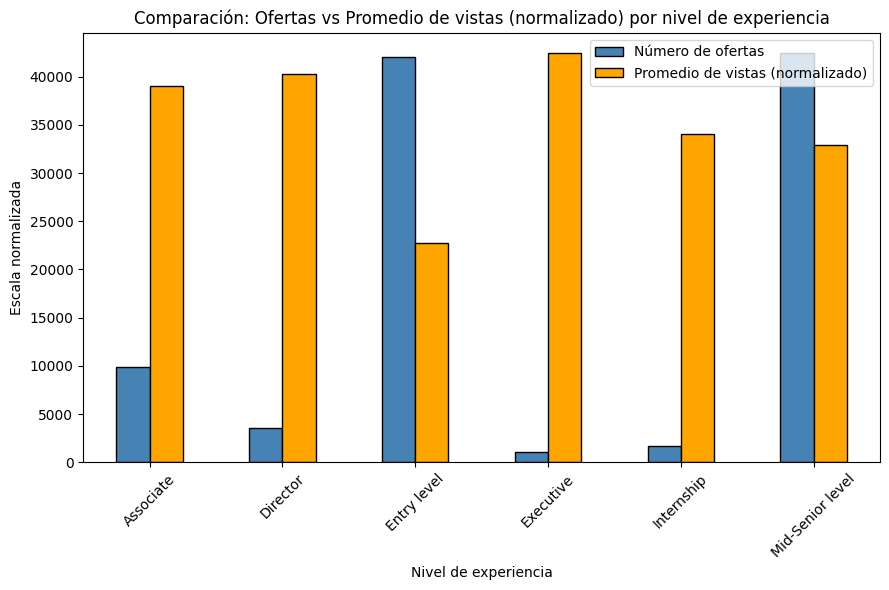

In [216]:
exp_summary = postings_no_duplicados.groupby('formatted_experience_level')['views'].agg(
    Número_de_ofertas='count',
    Promedio_de_vistas='mean'
)
exp_summary['Promedio_de_vistas_normalizado'] = (
    exp_summary['Promedio_de_vistas'] / exp_summary['Promedio_de_vistas'].max()
) * exp_summary['Número_de_ofertas'].max()

exp_summary[['Número_de_ofertas', 'Promedio_de_vistas_normalizado']].plot(
    kind='bar',
    figsize=(9,6),
    color=['steelblue','orange'],
    edgecolor='black'
)

plt.title('Comparación: Ofertas vs Promedio de vistas (normalizado) por nivel de experiencia')
plt.xlabel('Nivel de experiencia')
plt.ylabel('Escala normalizada')
plt.xticks(rotation=45)
plt.legend(['Número de ofertas', 'Promedio de vistas (normalizado)'])
plt.tight_layout()
plt.show()

En conjunto, el análisis revela un mercado con amplia oferta en los niveles intermedio y junior, pero con mayor competencia en los extremos, donde el número de interesados supera la disponibilidad real de vacantes.

### PROMEDIO DE VISITAS POR TIPO DE TRABAJO

Agrupamos los datos de ofertas de empleo por tipo de trabajo ('work_type') y calculamos el promedio de visitas (.mean()) para cada grupo.
Luego, utilizamos el método de trazado de pandas (.plot(kind='bar')) en la Serie resultante para generar un gráfico de barras vertical que muestra la relación entre el tipo de trabajo y su promedio de visitas.

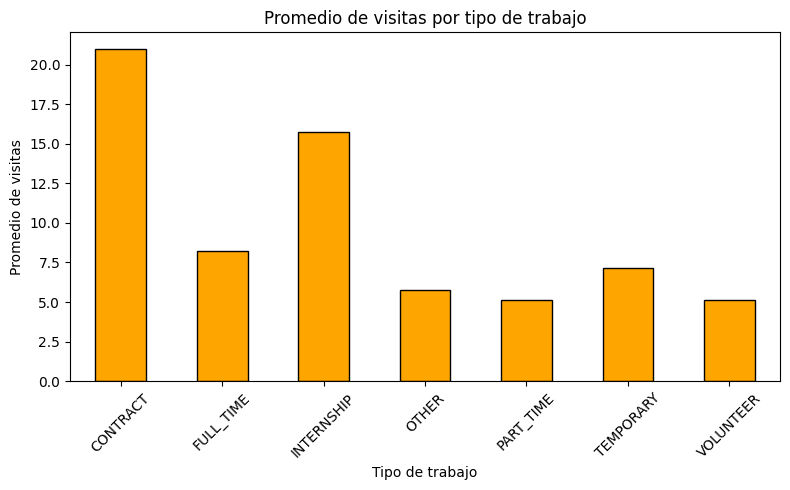

In [217]:
work_type_views = postings_no_duplicados.groupby('work_type')['views'].mean()

plt.figure(figsize=(8,5))
work_type_views.plot(kind='bar', color='orange', edgecolor='black')
plt.title('Promedio de visitas por tipo de trabajo')
plt.xlabel('Tipo de trabajo')
plt.ylabel('Promedio de visitas')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

El gráfico sugiere que los usuarios de LinkedIn muestran una clara preferencia por modalidades contractuales y de prácticas, frente a los empleos tradicionales a tiempo completo. Esto puede reflejar tanto una tendencia hacia la flexibilidad laboral como una fuerte competencia en los programas de prácticas.

### TOP 10 PUESTOS: OFERTAS VS PROMEDIO DE VISITAS

Primero Identificamos el Top 10 de puestos por número de ofertas (value_counts().head(10)) y calculamos el promedio de vistas para cada uno (groupby().mean()), combinando ambos en un DataFrame.

Luego, normalizamos la métrica de vistas para escalarla al rango del número de ofertas, permitiendo la comparación. Finalmente, genera un gráfico de barras horizontales superpuestas (plt.barh) para visualizar ambas métricas lado a lado para cada puesto.

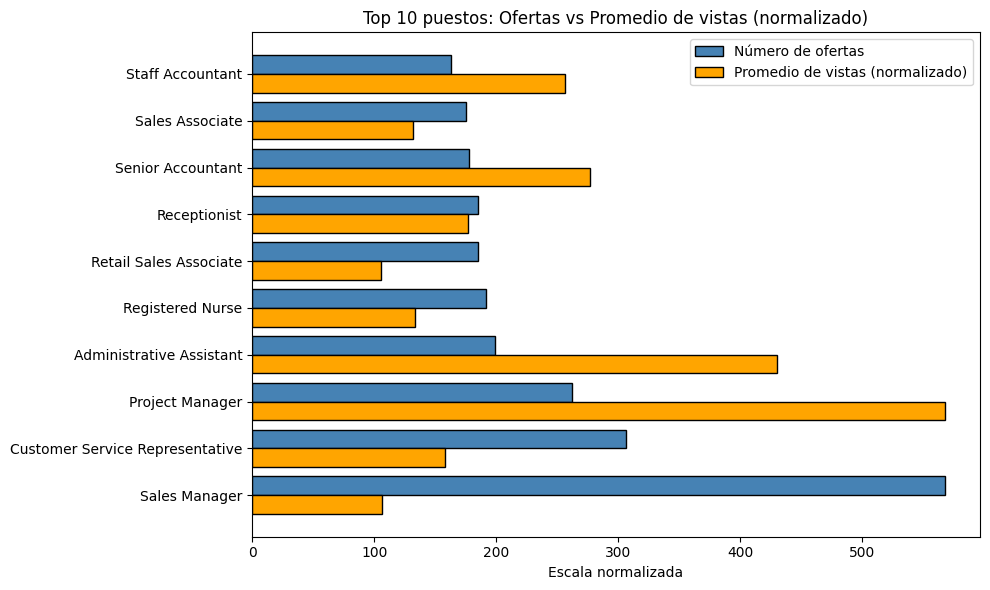

In [218]:
top = (postings_no_duplicados['title'].value_counts().head(10))
data = pd.DataFrame({
    'Número de ofertas': top,
    'Promedio de vistas': postings_no_duplicados.groupby('title')['views'].mean().reindex(top.index)
})

data['Promedio de vistas (norm)'] = (
    data['Promedio de vistas'] / data['Promedio de vistas'].max()
) * data['Número de ofertas'].max()

plt.figure(figsize=(10,6))
w = 0.4
x = range(len(data))

plt.barh([i + w/2 for i in x], data['Número de ofertas'], height=w, color='steelblue', edgecolor='black', label='Número de ofertas')
plt.barh([i - w/2 for i in x], data['Promedio de vistas (norm)'], height=w, color='orange', edgecolor='black', label='Promedio de vistas (normalizado)')

plt.yticks(x, data.index)
plt.title('Top 10 puestos: Ofertas vs Promedio de vistas (normalizado)')
plt.xlabel('Escala normalizada')
plt.legend()
plt.tight_layout()
plt.show()

El gráfico revela una clara desconexión entre la oferta y la demanda laboral: mientras algunos puestos con muchas vacantes generan poco interés, otros con pocas ofertas atraen una atención considerable. Este patrón sugiere que las preferencias de los candidatos no siempre coinciden con las necesidades del mercado, lo que puede influir en la competencia y dificultad de cubrir ciertos puestos.

### DISTRIBUCIÓN DE NIVELES DE EXPERIENCIA POR REGIÓN ZIP

Relacionamos las variables region y formatted_experience_level para ver el % de ofertas qué hay en cada región según el nivel de experiencia. Con .sort_index() ordenamos las filas según el índice del código postal.

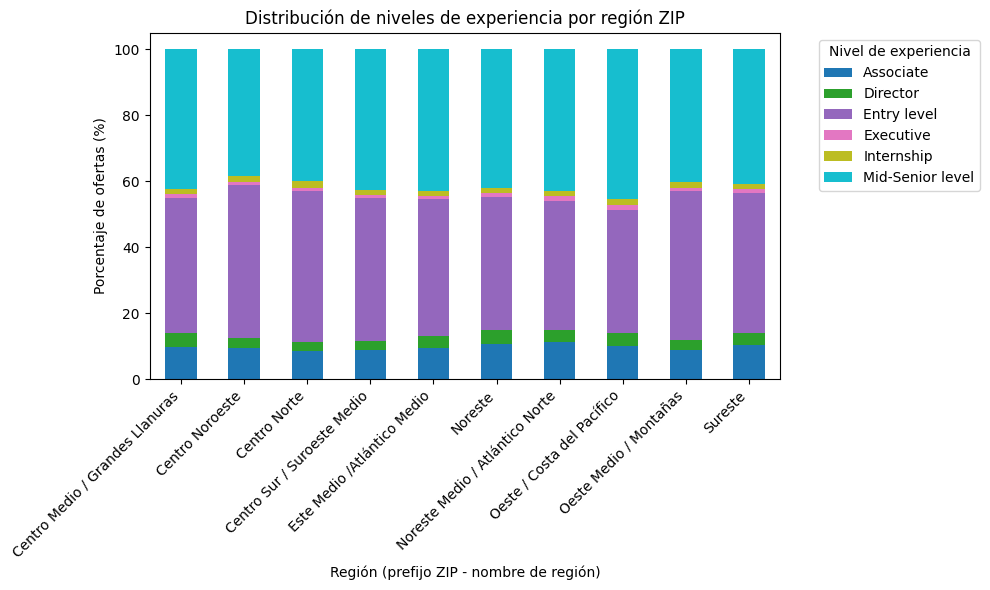

In [219]:
region_experience = postings_no_duplicados.groupby(['region', 'formatted_experience_level'])['region'].count().unstack(fill_value=0)
region_experience_percentage = region_experience.apply(lambda x: x / x.sum() * 100, axis=1).round(2)
region_experience_percentage = region_experience_percentage.sort_index()

region_experience_percentage.plot(kind='bar', stacked=True, figsize=(10,6), colormap='tab10')
plt.title('Distribución de niveles de experiencia por región ZIP')
plt.xlabel('Región (prefijo ZIP - nombre de región)')
plt.ylabel('Porcentaje de ofertas (%)')
plt.legend(title='Nivel de experiencia', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [220]:
region_experience_percentage

formatted_experience_level,Associate,Director,Entry level,Executive,Internship,Mid-Senior level
region,,,,,,
Centro Medio / Grandes Llanuras,9.87,4.01,41.18,1.01,1.57,42.37
Centro Noroeste,9.54,2.81,46.49,0.83,1.85,38.48
Centro Norte,8.40,2.93,45.78,0.98,1.89,40.01
Centro Sur / Suroeste Medio,8.75,2.92,43.31,0.93,1.42,42.66
Este Medio /Atlántico Medio,9.58,3.51,41.53,0.99,1.48,42.91
Noreste,10.53,4.35,40.39,1.03,1.59,42.10
Noreste Medio / Atlántico Norte,11.15,3.85,38.93,1.49,1.74,42.85
Oeste / Costa del Pacífico,9.94,3.93,37.56,1.26,1.83,45.48
Oeste Medio / Montañas,8.97,3.01,45.07,1.01,1.61,40.32


El patrón que siguen todas las regiones es muy parecido. El mayor % de ofertas está concentrado en Mid-Senior Level y en Entry Level. Esto nos indica que la mayoría de empresas buscan perfiles con cierta experiencia. Este comportamiento homogéneo puede deberse a la creciente globalización del mercado laboral y a la estandarización de perfiles profesionales demandados, especialmente en sectores digitales o tecnológicos como puede ser el nuestro.

### DISTRIBUCIÓN GEOGRÁFICA DE OFERTAS DE INTERNSHIPS

Ahora vamos a filtrar las ofertas de Internship que lo tenemos muy próximo en nuestra vida laboral. Calculamos y agrupamos las ofertas de prácticas por región(%).

C:\Users\david\AppData\Local\Temp\ipykernel_16120\3483424884.py:1: UserWarning:

Boolean Series key will be reindexed to match DataFrame index.



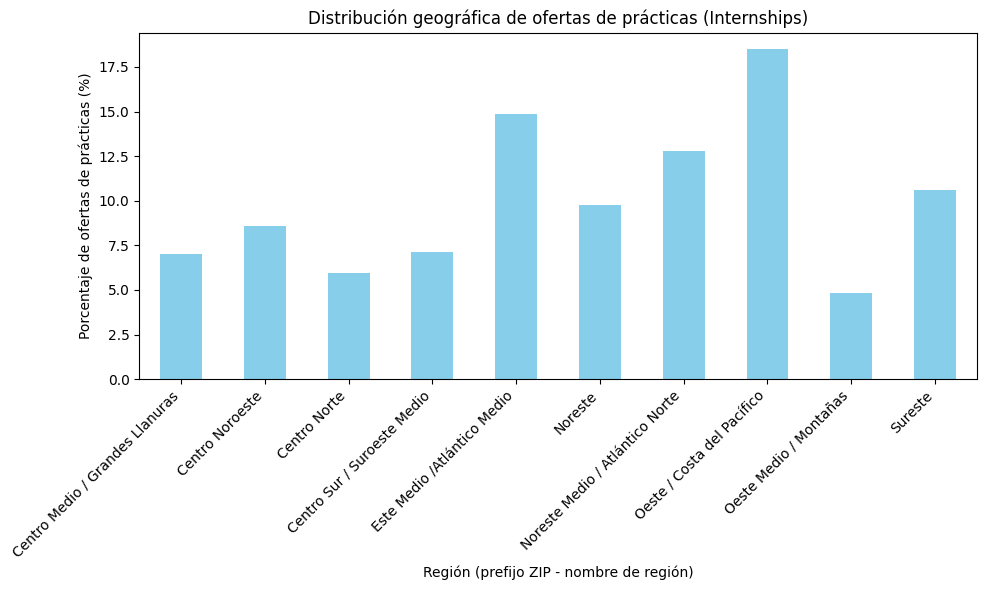

In [221]:
internship_df = postings_no_duplicados[postings['work_type'].str.lower() == 'internship']
tabla_internships = (
    internship_df
    .groupby('region')['region']
    .count()
)
tabla_internships_pct = (tabla_internships / tabla_internships.sum() * 100).round(2)
tabla_internships_pct

tabla_internships_pct.plot(kind='bar', color='skyblue', figsize=(10,6))
plt.title('Distribución geográfica de ofertas de prácticas (Internships)')
plt.xlabel('Región (prefijo ZIP - nombre de región)')
plt.ylabel('Porcentaje de ofertas de prácticas (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Tras obtener la gráfica, podemos ver que en Oeste/Costa del Pacífico se concentran casi un 20% de las oportunidades de Internships de todo el país. Esto nos indica que las oportunidades a las nuevas generaciones no están bien distribuidas en el territorio estadounidense. La Costa del Pacífico cuenta con California y Washington, dos grandes estados en los que abundan las empresas, startups y, también, las universidades. Esto conlleva a que se promuevan los programas de prácticas.
También destacan Este Medio, Noreste Medio y el Sureste. Sin embargo, el Sureste era la segunda región con menor % de Internships respecto a el resto de regiones. Aunque suene contradictorio no lo es, ya que esto se debe a la gran cantidad de ofertas totales que se concentran en esta región y eso hace que los Internships no se aprecien prácticamente en la anterior gráfica.


In [222]:
tabla_internships_pct

region
Centro Medio / Grandes Llanuras     6.99
Centro Noroeste                     8.59
Centro Norte                        5.97
Centro Sur / Suroeste Medio         7.13
Este Medio /Atlántico Medio        14.85
Noreste                             9.75
Noreste Medio / Atlántico Norte    12.81
Oeste / Costa del Pacífico         18.49
Oeste Medio / Montañas              4.80
Sureste                            10.63
Name: region, dtype: float64

### FORMATTED EXPERIENCE

Se analiza a continuación la variable que representa el nivel de experiencia ofertado a través de Linkedin.

In [223]:
postings['formatted_experience_level'].unique()

array(['Mid-Senior level', 'Director', 'Entry level', 'Associate',
       'Internship', 'Executive'], dtype=object)

In [224]:
postings['formatted_experience_level']

0         Mid-Senior level
1         Mid-Senior level
2                 Director
3                 Director
4              Entry level
                ...       
223393    Mid-Senior level
223394    Mid-Senior level
223395    Mid-Senior level
223396    Mid-Senior level
223397    Mid-Senior level
Name: formatted_experience_level, Length: 223398, dtype: object

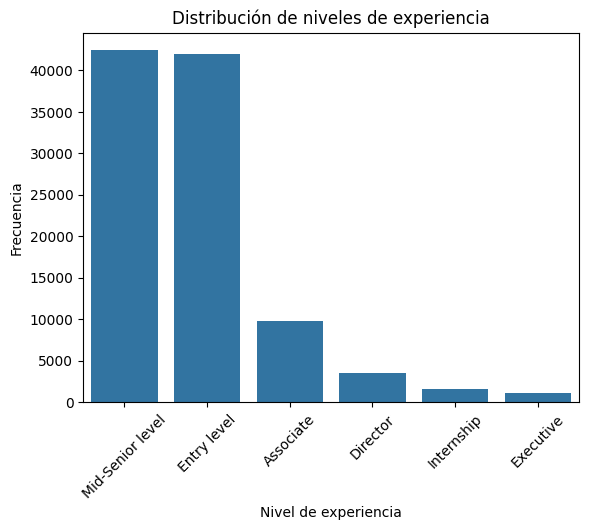

In [225]:
sns.countplot(                                                     
    data=postings_no_duplicados,                                       
    x='formatted_experience_level',                               
    order=postings['formatted_experience_level'].value_counts().index)   

plt.title('Distribución de niveles de experiencia')
plt.xlabel('Nivel de experiencia')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45)
plt.show()

Como se puede observar, el nivel de experiencia más ofertado es el Mid-Senior level, seguido de cerca por Entry level. Por otro lado sorprende que Internship sea de las puestos menos oferrtados.

### BENEFITS

En este apartado se analiza la distribución de los beneficios que se incluyen en las distintas ofertas de Linkedin.

In [226]:
benefits_df_raw = pd.read_csv('benefits.csv', sep=',')

In [227]:
benefits_df_raw.head()

,job_id,inferred,type
0,3887473071,0,Medical insurance
1,3887473071,0,Vision insurance
2,3887473071,0,Dental insurance
3,3887473071,0,401(k)
4,3887473071,0,Student loan assistance


In [228]:
benefits_df_raw.isna().sum()

job_id      0
inferred    0
type        0
dtype: int64

Como se aprecia en la ejecución superior, no existe ningún missing value en la tabla de datos.

A continuación depuramos la variable, nos quedamos unicamente con las columnas job_id y type y nos aseguramos de que no existan duplicados.

In [229]:
columns=['job_id','type']
benefits_df = benefits_df_raw[columns].copy()
benefits_df = benefits_df.drop_duplicates(subset=['job_id', 'type'])
benefits_df

,job_id,type
0,3887473071,Medical insurance
1,3887473071,Vision insurance
2,3887473071,Dental insurance
3,3887473071,401(k)
4,3887473071,Student loan assistance
...,...,...
67938,3902878689,Dental insurance
67939,3902878689,Pension plan
67940,3902878689,Tuition assistance
67941,3902878689,Disability insurance


Finalmente visualizamos los posibles valores y mostramos un gráfico de barras para observar la frecuencia de cada tipo de beneficio.

In [230]:
benefits_df['type'].unique()

array(['Medical insurance', 'Vision insurance', 'Dental insurance',
       '401(k)', 'Student loan assistance', 'Tuition assistance',
       'Disability insurance', 'Paid maternity leave',
       'Paid paternity leave', 'Child care support', 'Commuter benefits',
       'Pension plan'], dtype=object)

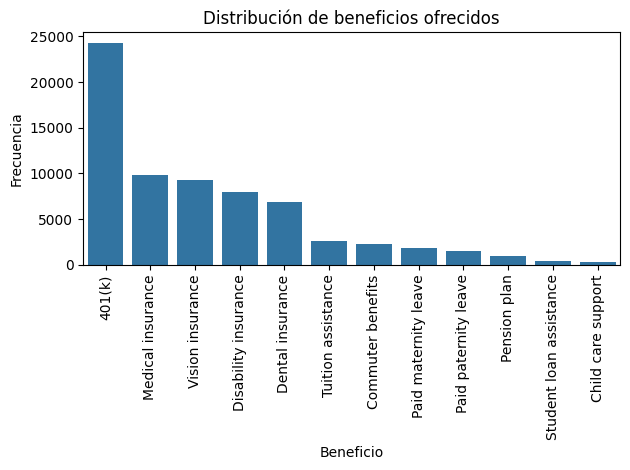

In [231]:
sns.countplot(
    data=benefits_df,
    x='type',
    order=benefits_df['type'].value_counts().index
)

plt.title('Distribución de beneficios ofrecidos')
plt.xlabel('Beneficio')
plt.ylabel('Frecuencia')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Se aprecia que el beneficio más ofrecido en EEUU a través de Linkedin es el 401(k), este beneficio consiste en un plan de pensiones especial, seguido por Seguro medico.

En adelante, se agrupa la tabla de beneficios a través del job_id y se hace un merge con la tabla principal, asegurando la concurrencia del tipo de dato.

In [232]:
benefits_jobid_grouped = benefits_df.groupby('job_id')['type'].apply(list).reset_index()

In [233]:
benefits_jobid_grouped

,job_id,type
0,23221523,[401(k)]
1,56482768,"[401(k), Dental insurance, Disability insurance]"
2,69333422,"[Medical insurance, Vision insurance, Dental i..."
3,95428182,"[Medical insurance, Dental insurance, Disabili..."
4,111513530,"[Medical insurance, Paid maternity leave, Pens..."
...,...,...
30018,3906266212,"[Dental insurance, Vision insurance, 401(k)]"
30019,3906266229,"[Medical insurance, Vision insurance, Dental i..."
30020,3906266248,"[401(k), Vision insurance, Medical insurance]"
30021,3906266272,"[Medical insurance, Vision insurance, Dental i..."


In [234]:
postings['job_id']=postings['job_id'].astype(str)
benefits_jobid_grouped['job_id']=benefits_jobid_grouped['job_id'].astype(str)
merged_benefits_jobid_grouped = pd.merge(postings, benefits_jobid_grouped, on='job_id', how='inner')
merged_benefits_jobid_grouped

,job_id,company_name,title,location,company_id,views,zip_code,work_type,formatted_experience_level,INDUSTRIA_COMPAÑIA,...,skill_name,ZIP,LAT,LNG,primer_digito_codigo_postal,region,ciudad,estado,estado_completo,type
0,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,"New Hyde Park, NY",766262,16.0,11040,FULL_TIME,Entry level,Law Practice,...,Other,11040,40.745347,-73.680292,1,Noreste Medio / Atlántico Norte,New Hyde Park,NY,New York,[401(k)]
1,95428182,CLEVELAND KIDS BOOK BANK,Administrative Coordinator,"Cleveland, OH",55624331,1.0,44102,FULL_TIME,Entry level,Non-profit Organizations,...,Administrative,44102,41.479174,-81.740603,4,Centro Noroeste,Cleveland,OH,Ohio,"[Medical insurance, Dental insurance, Disabili..."
2,117675818,Premier Family Clinic,Physician Assistant,"Atlanta, GA",4285947,29.0,30303,CONTRACT,Director,Hospitals and Health Care,...,Health Care Provider,30303,33.753259,-84.389953,3,Sureste,Atlanta,GA,Georgia,[Medical insurance]
3,229924287,REquipment Durable Medical Equipment and Assis...,Administrative Assistant,"Woburn, MA",14773918,3.0,01801,PART_TIME,Mid-Senior level,Medical Equipment Manufacturing,...,Administrative,01801,42.488769,-71.154438,0,Noreste,Woburn,MA,Massachusetts,"[Medical insurance, Dental insurance, Vision i..."
4,231010577,Pierce Refrigeration,Service / Construction Technician,"West Bridgewater, MA",6482450,3.0,02379,FULL_TIME,Mid-Senior level,Facilities Services,...,Management,02379,42.021617,-71.026717,0,Noreste,West Bridgewater,MA,Massachusetts,[401(k)]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53283,3906266272,"TalentBurst, an Inc 5000 company",Quality Engineer,"Irvine, CA",122451,1.0,92602,CONTRACT,Mid-Senior level,Staffing and Recruiting,...,Engineering,92602,33.754048,-117.752273,9,Oeste / Costa del Pacífico,Irvine,CA,California,"[Medical insurance, Vision insurance, Dental i..."
53284,3906266272,"TalentBurst, an Inc 5000 company",Quality Engineer,"Irvine, CA",122451,1.0,92602,CONTRACT,Mid-Senior level,Staffing and Recruiting,...,Engineering,92602,33.754048,-117.752273,9,Oeste / Costa del Pacífico,Irvine,CA,California,"[Medical insurance, Vision insurance, Dental i..."
53285,3906266272,"TalentBurst, an Inc 5000 company",Quality Engineer,"Irvine, CA",122451,1.0,92602,CONTRACT,Mid-Senior level,Staffing and Recruiting,...,Engineering,92602,33.754048,-117.752273,9,Oeste / Costa del Pacífico,Irvine,CA,California,"[Medical insurance, Vision insurance, Dental i..."
53286,3906267117,Lozano Smith,Title IX/Investigations Attorney,"Walnut Creek, CA",56120,1.0,94595,FULL_TIME,Mid-Senior level,Law Practice,...,Legal,94595,37.871950,-122.069383,9,Oeste / Costa del Pacífico,Walnut Creek,CA,California,"[Medical insurance, Vision insurance, Dental i..."


Finalmente, gracias al siguiente Heatmap se puede observar la relación entre el puesto ofertado y el beneficio que se incluye en el mismo.

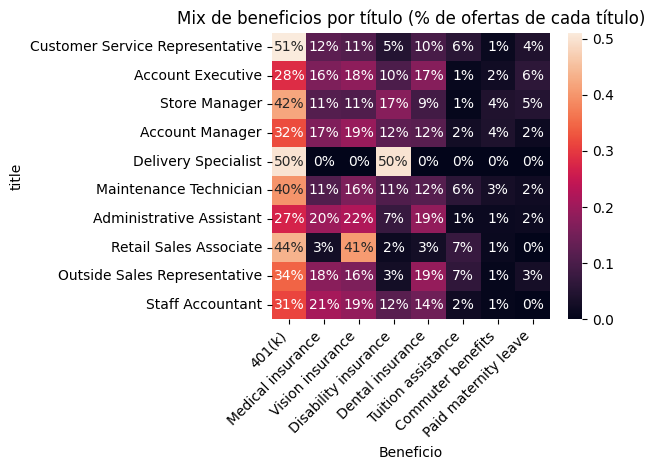

In [235]:
expl = merged_benefits_jobid_grouped.explode('type').dropna(subset=['type'])

top_titles   = merged_benefits_jobid_grouped['title'].value_counts().head(10).index
top_benefits = expl['type'].value_counts().head(8).index

sub = expl[expl['title'].isin(top_titles) & expl['type'].isin(top_benefits)]
tab = pd.crosstab(sub['title'], sub['type'])
tab_pct = tab.div(tab.sum(axis=1), axis=0)  # % dentro de cada título

sns.heatmap(tab_pct.loc[top_titles, top_benefits], annot=True, fmt='.0%')
plt.title('Mix de beneficios por título (% de ofertas de cada título)')
plt.xlabel('Beneficio'); plt.ylabel('title')
plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

Como se observa, el puesto de Customer Service Representative es el puesto con más beneficios incluidos, siendo este el 401(k). Además se aprecia un pico de relación entre el puesto de Delivery Specialist y el beneficio de Disability insurance.